# **Road Hazard Detection, Lane Estimation and Rule-Based Risk Assessment (CODA2022)**

**Course:** UTS 31256/42177 Image Processing and Pattern Recognition
**Team:** Team 7

---

## Pipeline overview

| Section | Content | Notebook location |
|---------|---------|-------------------|
| **A.1** | Setup and data preparation (splits, YOLO-format labels) | Part 1, steps 1.1 to 1.3 |
| **A.2** | Hazard detector training (YOLOv8s and Faster R-CNN) | Part 1, steps 1.4 and 1.5 |
| **A.3** | Detector inference and evaluation (COCO metrics, precision and recall) | Part 1, steps 1.6 to 1.10 |
| **A.4** | Lane detection (Canny, region of interest, Hough lines, validation) | Part 2 |
| **A.5** | Rule-based risk assessment and its evaluation | Parts 3 and 4 |

## Notes

- The code was run in Google Colab with a T4 GPU.
- Paths point to Google Drive.
- Each section is self-contained apart from the shared variables defined in A.1.

In [ ]:
!pip install -q ultralytics
import os, json, glob, shutil
import pandas as pd
import torch
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from ultralytics import YOLO
from google.colab import drive
drive.mount('/content/drive')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.4 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Part 1 - Hazard Detection

This section prepares the CODA2022 data, trains and tests the hazard detectors (YOLOv8s and Faster R-CNN), and evaluates them using mAP, precision and recall.

## 1.1 Inspecting the CODA2022 Dataset

The dataset folder is scanned to confirm that the images and annotation files are in the expected places, and the number of files in each folder is printed.

The validation annotation file is then loaded to check its structure. The number of images, bounding boxes and categories is printed, along with one example image entry and one example box entry, so the annotation format is clear before the data is converted for training.

In [ ]:
DATA_ROOT = '/content/drive/MyDrive/Coda2022-dataset'

print('Folders (with file counts):')
for dp, dn, fn in os.walk(DATA_ROOT):
    rel = os.path.relpath(dp, DATA_ROOT)
    print(f"  {rel}/  ->  {len(fn)} files, {len(dn)} subfolders")

ann = os.path.join(DATA_ROOT, 'CODA2022-val', 'annotations.json')
d = json.load(open(ann))
print('\nkeys:', list(d.keys()))
print('images:', len(d['images']), ' boxes:', len(d['annotations']), ' categories:', len(d['categories']))
print('example image entry:', d['images'][0])
print('example box entry  :', d['annotations'][0])

Folders (with file counts):
  ./  ->  0 files, 3 subfolders
  CODA2022-val/  ->  1 files, 1 subfolders
  CODA2022-val/images/  ->  4884 files, 0 subfolders
  CODA2022-test/  ->  1 files, 1 subfolders
  CODA2022-test/images/  ->  4884 files, 0 subfolders
  CODA-val-1500/  ->  0 files, 1 subfolders
  CODA-val-1500/CODA/  ->  0 files, 1 subfolders
  CODA-val-1500/CODA/base-val-1500/  ->  4 files, 1 subfolders
  CODA-val-1500/CODA/base-val-1500/images/  ->  1057 files, 0 subfolders

keys: ['images', 'categories', 'annotations']
images: 4884  boxes: 40835  categories: 29
example image entry: {'id': 1, 'file_name': '0001.jpg', 'height': 720, 'width': 1355, 'period': 'daytime', 'weather': 'clear'}
example box entry  : {'id': 1, 'image_id': 1, 'category_id': 20, 'corner_case': True, 'bbox': [1265, 560, 40, 157]}


## 1.2 Checking the Validation and Test Annotations

The validation and test folders are checked in more detail. First, the loose files in the test and extra folders are listed, then the validation and test annotation files are loaded and summarised (images, boxes and categories). A warning is printed if the test file has no boxes, because it could not then be used for final evaluation.

The number of boxes in each category is compared between validation and test. The validation images are also broken down by time of day, weather, corner-case boxes and image size, which are used later for the robustness results. Finally, the first 200 listed images in each split are checked to confirm that the image files exist.

In [ ]:
ROOT = '/content/drive/MyDrive/Coda2022-dataset'
VAL_DIR  = f'{ROOT}/CODA2022-val'
TEST_DIR = f'{ROOT}/CODA2022-test'
EXTRA_DIR = f'{ROOT}/CODA-val-1500/CODA/base-val-1500'

# What are the loose files in the test and extra folders?
for name, folder in [('test', TEST_DIR), ('base-val-1500', EXTRA_DIR)]:
    files = [f for f in os.listdir(folder) if os.path.isfile(f'{folder}/{f}')]
    print(f'{name} folder files:', files)

# Load validation and test annotations
val = json.load(open(f'{VAL_DIR}/annotations.json'))
test_json = sorted(glob.glob(f'{TEST_DIR}/*.json'))
test = json.load(open(test_json[0])) if test_json else None
print('test annotation file:', test_json[0] if test_json else 'NONE FOUND')

def summarise(name, d):
    print(f"{name}: {len(d['images'])} images, {len(d.get('annotations', []))} boxes, "
          f"{len(d['categories'])} categories listed")
summarise('validation', val)
if test:
    summarise('test', test)
    if not test.get('annotations'):
        print('WARNING: the test file has no boxes, so it cannot be used for final evaluation.')
print('report says: 4884 / 4884 images, 29 validation categories, 43 test categories')

# Boxes per category, validation vs test
def counts(d):
    names = {c['id']: c['name'] for c in d['categories']}
    return pd.Series([names[a['category_id']] for a in d.get('annotations', [])]).value_counts()
table = pd.DataFrame({'val_boxes': counts(val), 'test_boxes': counts(test) if test else 0}).fillna(0).astype(int)
print('\n', table.sort_values('val_boxes', ascending=False).to_string())

# Extra fields for the robustness breakdown
print('\nperiod :', pd.Series([im.get('period') for im in val['images']]).value_counts().to_dict())
print('weather:', pd.Series([im.get('weather') for im in val['images']]).value_counts().to_dict())
print('corner_case boxes:', sum(a.get('corner_case', False) for a in val['annotations']), 'of', len(val['annotations']))
print('image sizes:', pd.Series([(im['width'], im['height']) for im in val['images']]).value_counts().head(3).to_dict())

# Do the listed images exist? (first 200 of each)
for name, d, folder in [('val', val, f'{VAL_DIR}/images'), ('test', test, f'{TEST_DIR}/images')]:
    if d:
        gone = [im['file_name'] for im in d['images'][:200] if not os.path.exists(f"{folder}/{im['file_name']}")]
        print(f'{name}: {len(gone)} of the first 200 images missing', gone[:3])

test folder files: ['annotations.json']
base-val-1500 folder files: ['corner_case.json', 'kitti_indices.json', 'nuscenes_indices.json', 'README.md']
test annotation file: /content/drive/MyDrive/Coda2022-dataset/CODA2022-test/annotations.json
validation: 4884 images, 40835 boxes, 29 categories listed
test: 4884 images, 39345 boxes, 43 categories listed
report says: 4884 / 4884 images, 29 validation categories, 43 test categories

                       val_boxes  test_boxes
car                       15470       14961
pedestrian                 5343        4780
traffic_cone               4985        4720
construction_vehicle       2785        2824
truck                      2455        2631
cyclist                    2285        2018
bollard                    1822        1443
barrier                    1477        1506
misc                        787         740
bus                         730         737
tricycle                    652         699
traffic_sign                445       

## 1.3 Preparing the Data for YOLO Training

The CODA2022 validation set is converted into the format that YOLO needs. The saved train and internal validation splits and the class list are loaded, and the CODA category ids are mapped to consecutive class numbers (0 to 28), because YOLO requires them to start at 0.

The images are copied to the local Colab disk, which is much faster for training than reading from Drive. For each image, a label file is written with one line per object, in the YOLO format: class number, then the box centre and size, as fractions of the image width and height. Boxes that are clipped to the image and end up smaller than one pixel are skipped and counted.

Finally, a dataset file (`coda.yaml`) is written that tells YOLO where the training and validation images are and what the class names are. The cell can be re-run safely, because images that have already been copied are not copied again.

In [ ]:
print('GPU available:', torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')

ROOT     = '/content/drive/MyDrive/Coda2022-dataset'
OUT      = '/content/drive/MyDrive/ippr_outputs'
YOLO_DIR = '/content/yolo_data'   # local disk, much faster than Drive for training

assert os.path.exists(f'{OUT}/splits.json'), 'splits.json is missing: run the split cell first'
val     = json.load(open(f'{ROOT}/CODA2022-val/annotations.json'))
splits  = json.load(open(f'{OUT}/splits.json'))
classes = json.load(open(f'{OUT}/classes.json'))
cat_to_idx = {cid: i for i, cid in enumerate(classes['cat_ids'])}   # YOLO needs 0..28
names = classes['names']

images = {im['id']: im for im in val['images']}
anns = {}
for a in val['annotations']:
    anns.setdefault(a['image_id'], []).append(a)

def export(split_name, ids):
    """Copy images to local disk and write YOLO label files. Safe to re-run."""
    img_out, lbl_out = f'{YOLO_DIR}/images/{split_name}', f'{YOLO_DIR}/labels/{split_name}'
    os.makedirs(img_out, exist_ok=True); os.makedirs(lbl_out, exist_ok=True)
    n_boxes = n_skipped = 0
    for i in tqdm(ids, desc=split_name):
        im = images[i]
        src = f"{ROOT}/CODA2022-val/images/{im['file_name']}"
        dst = f"{img_out}/{im['file_name']}"
        if not os.path.exists(dst) or os.path.getsize(dst) != os.path.getsize(src):
            shutil.copy2(src, dst)
        W, H = im['width'], im['height']
        lines = []
        for a in anns.get(i, []):
            x, y, w, h = a['bbox']
            x1, y1, x2, y2 = max(0, x), max(0, y), min(W, x + w), min(H, y + h)
            if x2 - x1 < 1 or y2 - y1 < 1:
                n_skipped += 1
                continue
            lines.append(f"{cat_to_idx[a['category_id']]} {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} "
                         f"{(x2-x1)/W:.6f} {(y2-y1)/H:.6f}")
        n_boxes += len(lines)
        with open(f"{lbl_out}/{os.path.splitext(im['file_name'])[0]}.txt", 'w') as f:
            f.write('\n'.join(lines))
    return n_boxes, n_skipped

for split_name, key in [('train', 'train'), ('val', 'internal_val')]:
    n_boxes, n_skipped = export(split_name, splits[key])
    print(f'{split_name}: {len(splits[key])} images, {n_boxes} boxes written, {n_skipped} degenerate boxes skipped')

yaml_path = f'{YOLO_DIR}/coda.yaml'
with open(yaml_path, 'w') as f:
    f.write(f'path: {YOLO_DIR}\ntrain: images/train\nval: images/val\nnames:\n')
    f.writelines(f'  {i}: {n}\n' for i, n in enumerate(names))
print('classes:', len(names), '| dataset file:', yaml_path)

GPU available: True Tesla T4


train:   0%|          | 0/3907 [00:00<?, ?it/s]

train: 3907 images, 32660 boxes written, 0 degenerate boxes skipped


val:   0%|          | 0/977 [00:00<?, ?it/s]

val: 977 images, 8175 boxes written, 0 degenerate boxes skipped
classes: 29 | dataset file: /content/yolo_data/coda.yaml


## 1.4 Training the YOLOv8s Detector

YOLOv8s, pretrained on COCO, is fine-tuned on the CODA2022 training split. The two checks at the start confirm that a GPU is available and that the dataset file from the previous step exists.

The main training settings are:

- **Image size and batch:** images are resized to 960 pixels, with a batch size of 8 so the model fits on a T4 GPU.
- **Epochs:** up to 30 epochs, with early stopping if the validation score does not improve for 10 epochs. Mosaic augmentation is switched off for the last 5 epochs so the model finishes training on normal images.
- **Optimiser:** AdamW with a learning rate of 0.001.
- **Seed:** a fixed seed (42) so the run is repeatable.

The weights, training curves and metrics are saved to the output folder on Drive.

In [ ]:
assert torch.cuda.is_available(), 'No GPU: Runtime > Change runtime type > T4 GPU'
assert os.path.exists(f'{YOLO_DIR}/coda.yaml'), 'Run the data prep cell first'

model = YOLO('yolov8s.pt')
model.train(
    data=f'{YOLO_DIR}/coda.yaml',
    imgsz=960, batch=8, workers=2,
    epochs=30, close_mosaic=5,          # last 5 epochs without mosaic augmentation
    patience=10,
    optimizer='AdamW', lr0=0.001,
    seed=42,
    project=f'{OUT}/yolo_runs', name='yolov8s_coda_30ep', exist_ok=True,
    plots=True,
)

Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/coda.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_coda_30ep, nbs=64, nms=None, opset=None, optimize=False

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78a4fa020d70>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004

## 1.5 Training the Faster R-CNN Detector

Faster R-CNN with a ResNet-50 FPN backbone, pretrained on COCO, is fine-tuned on the same training split used for YOLO, so the two detectors can be compared fairly. The classification layer is replaced so the model predicts the 29 CODA classes plus a background class.

Each image is converted to a tensor, and boxes are clipped to the image. Boxes smaller than one pixel are dropped, and training images are flipped horizontally half of the time. Images are resized so the short side is 640 pixels (maximum 1280).

The model is trained for 5 epochs with a batch size of 4, using SGD with a learning rate of 0.005. The learning rate warms up over the first 500 steps and then decreases smoothly. Mixed precision is used to save memory and time, gradients are clipped for stability, and any step with an invalid loss is skipped.

A checkpoint is saved after every epoch, so training resumes from the last finished epoch if Colab disconnects. The final weights are saved as `frcnn_final.pt`.

In [ ]:
# ===== Faster R-CNN (ResNet-50 FPN, COCO-pretrained): fine-tune on the same train split =====
import os, json, math, time, random
import numpy as np, torch
from torchvision.io import read_image
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from tqdm.auto import tqdm

ROOT     = '/content/drive/MyDrive/Coda2022-dataset'
OUT      = '/content/drive/MyDrive/ippr_outputs'
YOLO_DIR = '/content/yolo_data'
FR_DIR   = f'{OUT}/frcnn'; os.makedirs(FR_DIR, exist_ok=True)

EPOCHS, BATCH, LR = 5, 4, 0.005        # LR follows the torchvision rule: 0.02 per 16 images
MIN_SIZE, MAX_SIZE = 640, 1280         # images are resized so the short side is 640 px
device = torch.device('cuda')
random.seed(42); np.random.seed(42); torch.manual_seed(42)

val_coco = json.load(open(f'{ROOT}/CODA2022-val/annotations.json'))
splits   = json.load(open(f'{OUT}/splits.json'))
classes  = json.load(open(f'{OUT}/classes.json'))
cat_ids, names = classes['cat_ids'], classes['names']
cat_to_label = {cid: i + 1 for i, cid in enumerate(cat_ids)}      # label 0 is background
images = {im['id']: im for im in val_coco['images']}
anns = {}
for a in val_coco['annotations']:
    anns.setdefault(a['image_id'], []).append(a)

def find_image(split, file_name):
    local = f'{YOLO_DIR}/images/{split}/{file_name}'               # fast local copy if it exists
    return local if os.path.exists(local) else f'{ROOT}/CODA2022-val/images/{file_name}'

class CodaDet(torch.utils.data.Dataset):
    def __init__(self, ids, split, train):
        self.ids, self.split, self.train = list(ids), split, train
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, k):
        i = self.ids[k]; im = images[i]
        img = read_image(find_image(self.split, im['file_name']))
        if img.shape[0] == 1:
            img = img.repeat(3, 1, 1)
        img = img[:3].float() / 255
        H, W = img.shape[-2:]
        boxes, labels = [], []
        for a in anns.get(i, []):
            x, y, w, h = a['bbox']
            x1, y1, x2, y2 = max(0, x), max(0, y), min(W, x + w), min(H, y + h)
            if x2 - x1 < 1 or y2 - y1 < 1:
                continue
            boxes.append([x1, y1, x2, y2]); labels.append(cat_to_label[a['category_id']])
        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor(labels, dtype=torch.int64)
        if self.train and random.random() < 0.5:                    # horizontal flip
            img = img.flip(-1)
            if len(boxes):
                boxes[:, [0, 2]] = W - boxes[:, [2, 0]]
        return img, {'boxes': boxes, 'labels': labels}

def collate(batch):
    return tuple(zip(*batch))

train_ds = CodaDet(splits['train'], 'train', train=True)
loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2,
                                     collate_fn=collate, drop_last=True, pin_memory=True)

model = fasterrcnn_resnet50_fpn(weights='DEFAULT', min_size=MIN_SIZE, max_size=MAX_SIZE,
                                box_detections_per_img=100)
in_f = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_f, len(cat_ids) + 1)
model.to(device)

params = [p for p in model.parameters() if p.requires_grad]
opt = torch.optim.SGD(params, lr=LR, momentum=0.9, weight_decay=1e-4)
scaler = torch.amp.GradScaler('cuda')

steps_per_epoch = len(loader); total_steps = EPOCHS * steps_per_epoch; warmup = 500
def lr_at(it):
    if it < warmup:
        return LR * (0.001 + 0.999 * it / warmup)
    p = (it - warmup) / max(1, total_steps - warmup)
    return LR * (0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * p)))

start_epoch, ck = 0, f'{FR_DIR}/last.pt'
if os.path.exists(ck):                                              # resume after a disconnect
    s = torch.load(ck, map_location=device)
    model.load_state_dict(s['model']); opt.load_state_dict(s['opt']); scaler.load_state_dict(s['scaler'])
    start_epoch = s['epoch'] + 1
    print('resuming from epoch', start_epoch + 1)

for epoch in range(start_epoch, EPOCHS):
    model.train(); t0 = time.time(); running = 0.0; n = 0
    bar = tqdm(loader, desc=f'epoch {epoch + 1}/{EPOCHS}')
    for step, (imgs, tgts) in enumerate(bar):
        it = epoch * steps_per_epoch + step
        for g in opt.param_groups:
            g['lr'] = lr_at(it)
        imgs = [im.to(device, non_blocking=True) for im in imgs]
        tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
        with torch.autocast('cuda'):
            loss = sum(model(imgs, tgts).values())
        if not torch.isfinite(loss):
            opt.zero_grad(set_to_none=True); continue
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, 10.0)
        scaler.step(opt); scaler.update()
        running += loss.item(); n += 1
        bar.set_postfix(loss=f'{running / n:.3f}')
    torch.save({'epoch': epoch, 'model': model.state_dict(), 'opt': opt.state_dict(),
                'scaler': scaler.state_dict()}, ck + '.tmp')
    os.replace(ck + '.tmp', ck)
    print(f'epoch {epoch + 1}: mean loss {running / max(n, 1):.3f}, {(time.time() - t0) / 60:.1f} min')

torch.save(model.state_dict(), f'{FR_DIR}/frcnn_final.pt')
print('saved', f'{FR_DIR}/frcnn_final.pt')

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 180MB/s]


resuming from epoch 6
saved /content/drive/MyDrive/ippr_outputs/frcnn/frcnn_final.pt


## 1.6 Generating Detections on the Validation and Test Sets

Both trained detectors are run on two sets of images: the internal validation split (held out from training) and the CODA2022 test set (4,884 images). The detections are saved so they can be evaluated and reused without running the models again.

The setup loads the annotations and the saved weights, then builds the list of images for each set. Two prediction functions are defined, one for YOLOv8s and one for Faster R-CNN. Both keep every detection down to a very low confidence of 0.001 and at most 100 per image, so that the full precision-recall curve is available for the mAP calculation. A confidence threshold is applied later, when precision and recall are measured at a fixed threshold.

Each detection is stored in COCO format: image id, category id, box (x, y, width, height) and score. The category ids are converted back from the model's class numbers to the original CODA category ids.

Each result is saved as `dets_<model>_<split>.json` in the evaluation folder. If a file already exists, it is loaded instead of running the model again, which saves a lot of time after a disconnect.

In [ ]:
!pip install -q ultralytics pycocotools
from google.colab import drive
drive.mount('/content/drive')
import os, json, time
import numpy as np, pandas as pd, torch
from tqdm.auto import tqdm
from ultralytics import YOLO
from torchvision.io import read_image
from torchvision.models.detection import fasterrcnn_resnet50_fpn

ROOT     = '/content/drive/MyDrive/Coda2022-dataset'
OUT      = '/content/drive/MyDrive/ippr_outputs'
YOLO_DIR = '/content/yolo_data'
YOLO_W   = f'{OUT}/yolo_runs/yolov8s_coda_30ep/weights/best.pt'
FRCNN_W  = f'{OUT}/frcnn/frcnn_final.pt'
EVAL_DIR = f'{OUT}/eval'; os.makedirs(EVAL_DIR, exist_ok=True)

val_coco  = json.load(open(f'{ROOT}/CODA2022-val/annotations.json'))
test_coco = json.load(open(f'{ROOT}/CODA2022-test/annotations.json'))
splits    = json.load(open(f'{OUT}/splits.json'))
classes   = json.load(open(f'{OUT}/classes.json'))
cat_ids   = classes['cat_ids']
val_images = {im['id']: im for im in val_coco['images']}

def val_path(i):
    fn = val_images[i]['file_name']
    local = f'{YOLO_DIR}/images/val/{fn}'
    return local if os.path.exists(local) else f'{ROOT}/CODA2022-val/images/{fn}'

ival_items = [(val_path(i), i) for i in sorted(splits['internal_val'])]
test_items = [(f"{ROOT}/CODA2022-test/images/{im['file_name']}", im['id'])
              for im in sorted(test_coco['images'], key=lambda x: x['id'])]

def det(iid, cat, x1, y1, x2, y2, score):
    return {'image_id': int(iid), 'category_id': int(cat),
            'bbox': [round(float(x1), 2), round(float(y1), 2), round(float(x2 - x1), 2), round(float(y2 - y1), 2)],
            'score': round(float(score), 4)}

def predict_yolo(weights, items, bs=16):
    m = YOLO(weights); out = []
    for s0 in tqdm(range(0, len(items), bs), desc='YOLOv8'):
        chunk = items[s0:s0 + bs]
        res = m.predict([p for p, _ in chunk], imgsz=960, conf=0.001, iou=0.6, max_det=100,
                        half=True, verbose=False)
        for (p, iid), r in zip(chunk, res):
            if r.boxes is None or len(r.boxes) == 0:
                continue
            xyxy = r.boxes.xyxy.cpu().numpy(); sc = r.boxes.conf.cpu().numpy()
            cl = r.boxes.cls.cpu().numpy().astype(int)
            for b, sco, c in zip(xyxy, sc, cl):
                out.append(det(iid, cat_ids[c], b[0], b[1], b[2], b[3], sco))
    return out

def predict_frcnn(weights, items, bs=4):
    m = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None, num_classes=len(cat_ids) + 1,
                                min_size=640, max_size=1280, box_detections_per_img=100,
                                box_score_thresh=0.001)
    m.load_state_dict(torch.load(weights, map_location='cuda')); m.cuda().eval(); out = []
    with torch.no_grad():
        for s0 in tqdm(range(0, len(items), bs), desc='Faster R-CNN'):
            chunk = items[s0:s0 + bs]; imgs = []
            for p, _ in chunk:
                im = read_image(p)
                if im.shape[0] == 1:
                    im = im.repeat(3, 1, 1)
                imgs.append((im[:3].float() / 255).cuda())
            with torch.autocast('cuda'):
                outs = m(imgs)
            for (p, iid), o in zip(chunk, outs):
                b = o['boxes'].float().cpu().numpy(); sc = o['scores'].float().cpu().numpy()
                lb = o['labels'].cpu().numpy()
                for bb, sco, l in zip(b, sc, lb):
                    out.append(det(iid, cat_ids[int(l) - 1], bb[0], bb[1], bb[2], bb[3], sco))
    del m; torch.cuda.empty_cache()
    return out

DETS = {}
for name, fn, w in [('yolov8s', predict_yolo, YOLO_W), ('frcnn', predict_frcnn, FRCNN_W)]:
    for split, items in [('internal_val', ival_items), ('test', test_items)]:
        path = f'{EVAL_DIR}/dets_{name}_{split}.json'
        if os.path.exists(path):                       # cached from an earlier run
            DETS[(name, split)] = json.load(open(path)); continue
        t0 = time.time(); d = fn(w, items)
        json.dump(d, open(path, 'w')); DETS[(name, split)] = d
        print(f'{name} {split}: {len(d)} detections, {(time.time() - t0) / 60:.1f} min')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1.7 Evaluating the Detectors

The detections are compared with the ground-truth boxes using two kinds of measure. The evaluation is run on the internal validation split and on the CODA2022 test set. For the test set, only the 29 categories shared with the training data are scored.

**COCO metrics.** `coco_metrics` uses the standard COCO evaluation. It reports mAP50 (mean average precision at an IoU of 0.50), mAP50-95 (averaged over IoU thresholds from 0.50 to 0.95) and AR100 (average recall with up to 100 detections per image). It also returns the AP50 of each class.

**Precision and recall at a fixed threshold.** `pr_at` measures precision and recall using only detections with a confidence of at least 0.25 and an IoU of at least 0.5. Detections are matched to ground-truth boxes of the same class in the same image, starting with the highest score, and each ground-truth box can be matched only once. Matched detections are true positives, unmatched detections are false positives, and unmatched ground-truth boxes are false negatives.

Three tables are produced and saved as CSV files: the main results for both models and both splits, the per-class AP50 and recall on the test set, and a robustness breakdown by time of day on the test set.

In [ ]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import contextlib, io, copy

names  = dict(zip(cat_ids, classes['names']))
shared = set(cat_ids)                                   # the 29 categories shared by val and test
ival_set = set(splits['internal_val'])
GT = {
    'internal_val': ([val_images[i] for i in sorted(ival_set)],
                     [a for a in val_coco['annotations'] if a['image_id'] in ival_set]),
    'test': (sorted(test_coco['images'], key=lambda x: x['id']),
             [a for a in test_coco['annotations'] if a['category_id'] in shared]),
}

def coco_metrics(gt_images, gt_anns, dets, img_ids=None):
    ids = {im['id'] for im in gt_images} if img_ids is None else set(img_ids)
    A = []
    for k, a in enumerate([a for a in gt_anns if a['image_id'] in ids], 1):
        a = dict(a); a['id'] = k; a['iscrowd'] = 0; a['area'] = a['bbox'][2] * a['bbox'][3]; A.append(a)
    g = COCO()
    g.dataset = {'images': [im for im in gt_images if im['id'] in ids], 'annotations': A,
                 'categories': [{'id': c, 'name': names[c]} for c in cat_ids]}
    D = [d for d in dets if d['image_id'] in ids]
    with contextlib.redirect_stdout(io.StringIO()):
        g.createIndex()
        e = COCOeval(g, g.loadRes(copy.deepcopy(D)), 'bbox'); e.params.maxDets = [1, 10, 100]
        e.evaluate(); e.accumulate(); e.summarize()
    prec = e.eval['precision']                          # [IoU, recall, class, area, maxDets]
    per_class = {}
    for k, c in enumerate(e.params.catIds):
        p = prec[0, :, k, 0, -1]                        # IoU 0.50
        per_class[names[c]] = float(p[p > -1].mean()) if (p > -1).any() else float('nan')
    return {'mAP50-95': float(e.stats[0]), 'mAP50': float(e.stats[1]), 'AR100': float(e.stats[8]),
            'per_class_AP50': per_class}

def iou_xywh(a, b):
    ix = max(0.0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    inter = ix * iy; union = a[2] * a[3] + b[2] * b[3] - inter
    return inter / union if union > 0 else 0.0

def pr_at(gt_images, gt_anns, dets, conf=0.25, thr=0.5, img_ids=None):
    """Precision and recall at a fixed confidence and IoU. Class-aware greedy matching."""
    ids = {im['id'] for im in gt_images} if img_ids is None else set(img_ids)
    gt_by, dt_by = {}, {}
    for a in gt_anns:
        if a['image_id'] in ids:
            gt_by.setdefault((a['image_id'], a['category_id']), []).append(a['bbox'])
    for d in dets:
        if d['score'] >= conf and d['image_id'] in ids:
            dt_by.setdefault((d['image_id'], d['category_id']), []).append(d)
    per = {c: [0, 0, 0] for c in cat_ids}               # tp, fp, fn
    for key in set(gt_by) | set(dt_by):
        G = gt_by.get(key, []); used = [False] * len(G); c = key[1]
        for d in sorted(dt_by.get(key, []), key=lambda d: -d['score']):
            best, bi = 0.0, -1
            for gi, g in enumerate(G):
                if not used[gi]:
                    v = iou_xywh(g, d['bbox'])
                    if v >= thr and v > best:
                        best, bi = v, gi
            if bi >= 0:
                used[bi] = True; per[c][0] += 1
            else:
                per[c][1] += 1
        per[c][2] += used.count(False)
    tp = sum(v[0] for v in per.values()); fp = sum(v[1] for v in per.values()); fn = sum(v[2] for v in per.values())
    P = tp / (tp + fp) if tp + fp else 0.0; R = tp / (tp + fn) if tp + fn else 0.0
    per_recall = {names[c]: (v[0] / (v[0] + v[2]) if v[0] + v[2] else float('nan')) for c, v in per.items()}
    return {'precision': P, 'recall': R, 'per_class_recall': per_recall}

# ---- main table
rows, per_class = [], {}
for (name, split), dets in DETS.items():
    imgs, an = GT[split]
    m = coco_metrics(imgs, an, dets); p = pr_at(imgs, an, dets)
    rows.append({'model': name, 'split': split, 'precision@0.25': p['precision'], 'recall@0.25': p['recall'],
                 'mAP50': m['mAP50'], 'mAP50-95': m['mAP50-95'], 'AR100': m['AR100']})
    per_class[(name, split)] = (m['per_class_AP50'], p['per_class_recall'])
table = pd.DataFrame(rows).round(3)
display(table)
table.to_csv(f'{EVAL_DIR}/main_results.csv', index=False)

# ---- per-class table (test set)
pc = pd.DataFrame({f'{n}_AP50': per_class[(n, 'test')][0] for n in ['yolov8s', 'frcnn']} |
                  {f'{n}_recall': per_class[(n, 'test')][1] for n in ['yolov8s', 'frcnn']}).round(3)
pc['test_boxes'] = pd.Series({names[c]: sum(a['category_id'] == c for a in GT['test'][1]) for c in cat_ids})
display(pc.sort_values('test_boxes', ascending=False))
pc.to_csv(f'{EVAL_DIR}/per_class_test.csv')

# ---- robustness: by time of day (test set)
rows = []
test_imgs, test_an = GT['test']
for name in ['yolov8s', 'frcnn']:
    for period in sorted({im.get('period', 'unknown') for im in test_imgs}):
        ids = [im['id'] for im in test_imgs if im.get('period', 'unknown') == period]
        m = coco_metrics(test_imgs, test_an, DETS[(name, 'test')], ids)
        p = pr_at(test_imgs, test_an, DETS[(name, 'test')], img_ids=ids)
        rows.append({'model': name, 'period': period, 'images': len(ids), 'precision@0.25': p['precision'],
                     'recall@0.25': p['recall'], 'mAP50': m['mAP50']})
period_table = pd.DataFrame(rows).round(3)
display(period_table)
period_table.to_csv(f'{EVAL_DIR}/by_period_test.csv', index=False)

,model,split,precision@0.25,recall@0.25,mAP50,mAP50-95,AR100
0,yolov8s,internal_val,0.766,0.783,0.525,0.364,0.499
1,yolov8s,test,0.758,0.770,0.484,0.339,0.482
2,frcnn,internal_val,0.502,0.815,0.433,0.276,0.431
3,frcnn,test,0.490,0.812,0.405,0.255,0.421


,yolov8s_AP50,frcnn_AP50,yolov8s_recall,frcnn_recall,test_boxes
car,0.889,0.872,0.865,0.895,14961
pedestrian,0.739,0.722,0.691,0.792,4780
traffic_cone,0.879,0.839,0.864,0.877,4720
construction_vehicle,0.908,0.910,0.900,0.922,2824
truck,0.707,0.661,0.681,0.740,2631
cyclist,0.702,0.666,0.677,0.759,2018
barrier,0.571,0.509,0.559,0.645,1506
bollard,0.619,0.557,0.622,0.688,1443
misc,0.685,0.685,0.654,0.673,740
bus,0.611,0.593,0.582,0.649,737


,model,period,images,precision@0.25,recall@0.25,mAP50
0,yolov8s,dawn&dusk,237,0.742,0.762,0.463
1,yolov8s,daytime,3435,0.766,0.771,0.490
2,yolov8s,night,1212,0.730,0.766,0.468
3,frcnn,dawn&dusk,237,0.463,0.798,0.425
4,frcnn,daytime,3435,0.499,0.816,0.409
5,frcnn,night,1212,0.458,0.802,0.412


## 1.8 Saving Training Curves and Qualitative Comparison

Two things are produced for the report in this step.

First, the YOLO training outputs (training curves, normalised confusion matrix, precision-recall curve and the results table) are copied from the training run folder into the evaluation folder, so all the report material is in one place. A message is printed for each file to show whether it was copied or was missing.

Second, a side-by-side comparison of the two detectors is drawn on six random test images, using a fixed seed so the same images are shown each time. YOLOv8s is shown on the left (green boxes) and Faster R-CNN on the right (red boxes). Only detections with a confidence of at least 0.4 are drawn, and each box is labelled with its class and score. The figure is saved as `qualitative_test.png`.

copied results.png
copied confusion_matrix_normalized.png
missing PR_curve.png
copied results.csv


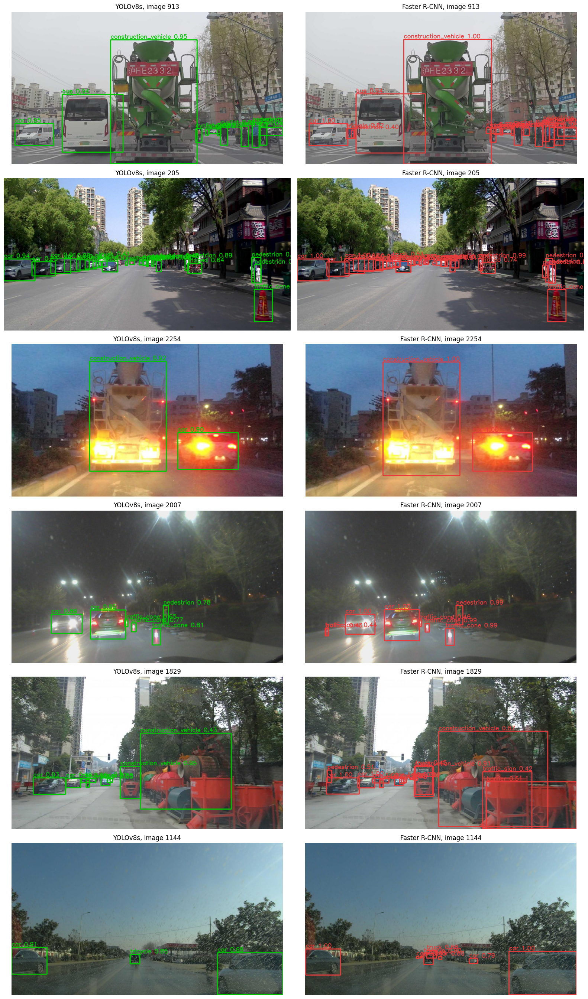

saved /content/drive/MyDrive/ippr_outputs/eval/qualitative_test.png


In [ ]:
import os, random, shutil
import cv2
import matplotlib.pyplot as plt

ROOT = '/content/drive/MyDrive/Coda2022-dataset'
OUT = '/content/drive/MyDrive/ippr_outputs'
RUN = f'{OUT}/yolo_runs/yolov8s_coda_30ep'
SHOW_CONF = 0.4
N_IMAGES = 6

# 1. Copy YOLO training curves and curves from the run folder into eval/
for f in ['results.png', 'confusion_matrix_normalized.png', 'PR_curve.png', 'results.csv']:
    src = f'{RUN}/{f}'
    if os.path.exists(src):
        shutil.copy(src, f'{EVAL_DIR}/yolo_{f}')
        print('copied', f)
    else:
        print('missing', f)

# 2. Qualitative comparison on random test images
cat_name = {c['id']: c['name'] for c in test_coco['categories']}
img_by_id = {im['id']: im for im in test_coco['images']}

def by_image(dets):
    d = {}
    for x in dets:
        if x['score'] >= SHOW_CONF:
            d.setdefault(x['image_id'], []).append(x)
    return d

yolo_d = by_image(DETS[('yolov8s', 'test')])
frcnn_d = by_image(DETS[('frcnn', 'test')])

random.seed(42)
ids = random.sample(sorted(img_by_id), N_IMAGES)

def draw(img, dets, color):
    img = img.copy()
    for x in dets:
        bx, by, bw, bh = [int(v) for v in x['bbox']]
        cv2.rectangle(img, (bx, by), (bx + bw, by + bh), color, 3)
        label = f"{cat_name.get(x['category_id'], x['category_id'])} {x['score']:.2f}"
        cv2.putText(img, label, (bx, max(by - 6, 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, 2)
    return img

fig, axes = plt.subplots(N_IMAGES, 2, figsize=(16, 4.5 * N_IMAGES))
for row, iid in enumerate(ids):
    fn = img_by_id[iid]['file_name']
    path = f'{ROOT}/CODA2022-test/images/{fn}'
    if not os.path.exists(path):
        path = f'{ROOT}/CODA2022-test/images/{os.path.basename(fn)}'
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    axes[row, 0].imshow(draw(img, yolo_d.get(iid, []), (0, 200, 0)))
    axes[row, 1].imshow(draw(img, frcnn_d.get(iid, []), (230, 60, 60)))
    axes[row, 0].set_title(f'YOLOv8s, image {iid}')
    axes[row, 1].set_title(f'Faster R-CNN, image {iid}')
    axes[row, 0].axis('off'); axes[row, 1].axis('off')
plt.tight_layout()
plt.savefig(f'{EVAL_DIR}/qualitative_test.png', dpi=110)
plt.show()
print('saved', f'{EVAL_DIR}/qualitative_test.png')

## 1.9 Copying the Precision-Recall Curve

In this version of YOLO the precision-recall curve is saved as `BoxPR_curve.png`, not `PR_curve.png`, so it was not copied in the previous step. It is copied here and saved as `yolo_PR_curve.png` with the other training outputs.

In [ ]:
import shutil

# The precision-recall curve is saved as BoxPR_curve.png in this version of YOLO,
# so it was not found by the previous copy step
src = f'{RUN}/BoxPR_curve.png'
shutil.copy(src, f'{EVAL_DIR}/yolo_PR_curve.png')
print('copied BoxPR_curve.png')

copied BoxPR_curve.png


## 1.10 Checking the Saved YOLO Test Detections

The saved YOLOv8s detections for the test set are loaded to confirm that the file is correct. The total number of detections is printed along with the first entry, so the format (image id, category id, box and score) can be seen. The number of detections with a confidence of at least 0.25 is also counted. This is the confidence threshold used by the lane detection and risk assessment sections that come after this one.

In [ ]:
import json

# Load the saved YOLOv8s detections for the test set
d = json.load(open(f'{EVAL_DIR}/dets_yolov8s_test.json'))

# Total number of detections and one example entry
print(len(d), d[0])

# Number of detections kept at the 0.25 confidence threshold
print(sum(x['score'] >= 0.25 for x in d), 'detections at score >= 0.25')

279958 {'image_id': 1, 'category_id': 3, 'bbox': [0.0, 316.03, 314.78, 402.78], 'score': 0.9402}
39630 detections at score >= 0.25


# Part 2 — Lane Detection
This section implements lane detection using Canny edge detection, Region of Interest (ROI) selection, and the Hough Transform.

# Importing Libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Importing libraries

import os
import json
import random
import pandas as pd
import cv2
import numpy as np
import matplotlib.pyplot as plt

Mounted at /content/drive


# 1. Loading Test Data and YOLO Detections

The CODA test annotations and YOLO detection results are loaded. The annotation file contains information about the test images and hazard classes, while the YOLO file contains the predicted hazards.

In [ ]:
root_path = '/content/drive/MyDrive/Coda2022-dataset'
output_path = '/content/drive/MyDrive/ippr_outputs'

test_path = os.path.join(root_path, 'CODA2022-test')
eval_path = os.path.join(output_path, 'eval')
yolo_path = os.path.join(eval_path, 'dets_yolov8s_test.json')

# Loading test annotations

with open(os.path.join(test_path, 'annotations.json'), 'r') as file:
    test_data = json.load(file)

# Loading YOLO detections

with open(yolo_path, 'r') as file:
    yolo_detections = json.load(file)


# Storing image information by image ID

images_by_id = {}

for image in test_data['images']:
    image_id = image['id']
    images_by_id[image_id] = image


# Storing category names by category ID

category_names = {}

for category in test_data['categories']:
    category_id = category['id']
    category_name = category['name']

    category_names[category_id] = category_name


print("Test images:", len(images_by_id))
print("YOLO detections:", len(yolo_detections))

print("\nExample detection:")
print(yolo_detections[0])

Test images: 4884
YOLO detections: 279958

Example detection:
{'image_id': 1, 'category_id': 3, 'bbox': [0.0, 316.03, 314.78, 402.78], 'score': 0.9402}


# 2. Filtering YOLO Detections

YOLO detections with a confidence score below 0.25 are removed. The remaining detections are then grouped by image ID so that the hazards detected in each image can be accessed together.

In [ ]:
confidence_threshold = 0.25

filtered_detections = []

for detection in yolo_detections:

  if detection['score'] >= confidence_threshold:
    filtered_detections.append(detection)


# Grouping detections by image

detections_by_image = {}

for detection in filtered_detections:

    image_id = detection['image_id']

    if image_id not in detections_by_image:
        detections_by_image[image_id] = []

    detections_by_image[image_id].append(detection)

print("All detections:", len(yolo_detections))
print("Detections above threshold:", len(filtered_detections))
print("Images with detected hazards:", len(detections_by_image))

All detections: 279958
Detections above threshold: 39630
Images with detected hazards: 4868


# 3. Loading a Sample Image

A random test image containing a detected hazard is loaded and displayed. This image will be used to test the lane detection steps.

In [ ]:
def load_test_image(image_id):

    image_info = images_by_id[image_id]
    filename = image_info['file_name']

    image_path = os.path.join(test_path, 'images', filename)

    if not os.path.exists(image_path):
        filename = os.path.basename(filename)
        image_path = os.path.join(test_path, 'images', filename)

    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError("Could not load: " + image_path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    return image


random.seed(42)

image_ids = list(detections_by_image.keys())

# Choose a random image
sample_id = random.choice(image_ids)
sample_image = load_test_image(sample_id)

print("Sample image:", sample_id)


Sample image: 915


Image ID: 915
Image dimensions: (720, 1281, 3)
Detected hazards: 10


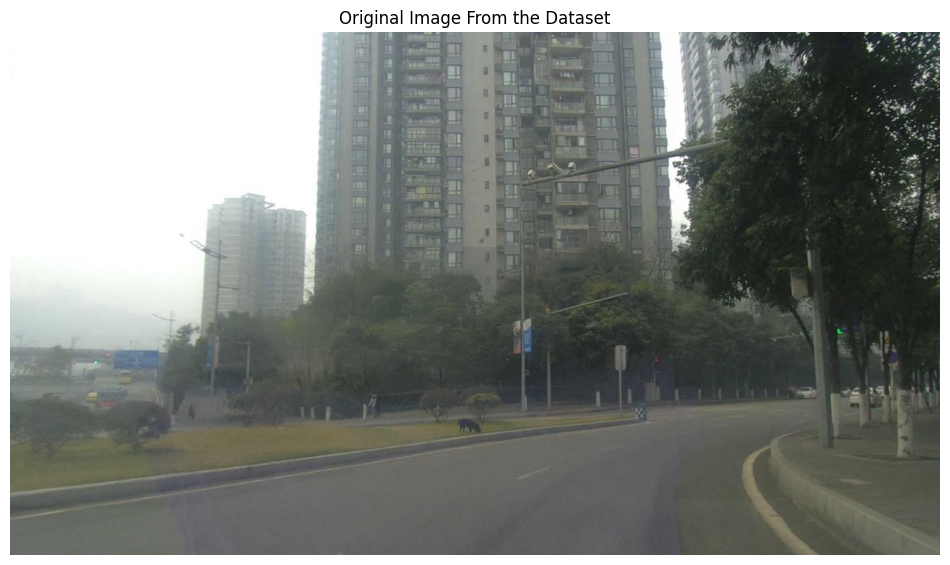

In [ ]:
print("Image ID:", sample_id)
print("Image dimensions:", sample_image.shape)
print("Detected hazards:", len(detections_by_image[sample_id]))

plt.figure(figsize=(12, 7))
plt.imshow(sample_image)
plt.title("Original Image From the Dataset")
plt.axis("off")
plt.show()

# 4. Image Preprocessing

The image is converted to grayscale to simplify the image information.

Gaussian blur is then applied to reduce noise before Canny Edge Detection is used to identify edges in the image.

In [ ]:
def preprocess_image(
    image,
    canny_low=30,
    canny_high=100
):

    # Convert image to grayscale
    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    # Reduce image noise
    blurred = cv2.GaussianBlur(
        gray,
        (5, 5),
        0
    )

    # Detect edges
    edges = cv2.Canny(
        blurred,
        canny_low,
        canny_high
    )

    return gray, blurred, edges

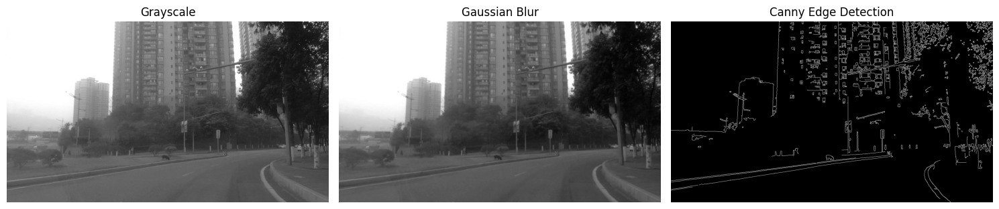

In [ ]:
gray, blurred, edges = preprocess_image(
    sample_image,
    30,
    100
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(blurred, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

## Canny Threshold Experiment

Three Canny threshold combinations are tested. Lower thresholds detect more edges but may include more noise, while higher thresholds detect fewer but stronger edges.

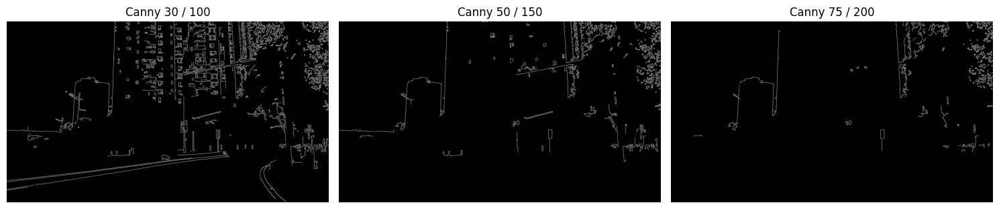

In [ ]:
# Testing different Canny thresholds

canny_settings = [
    (30, 100),
    (50, 150),
    (75, 200)
]

plt.figure(figsize=(15, 5))

for i in range(len(canny_settings)):

    low = canny_settings[i][0]
    high = canny_settings[i][1]

    test_gray, test_blurred, test_edges = preprocess_image(
        sample_image,
        low,
        high
    )

    plt.subplot(1, 3, i + 1)
    plt.imshow(test_edges, cmap="gray")
    plt.title("Canny " + str(low) + " / " + str(high))
    plt.axis("off")

plt.tight_layout()
plt.show()

**Observation:**

The 30/100 thresholds retained more of the weaker road and lane edges. Higher thresholds removed more noise but also removed useful road edges. Therefore, 30/100 was selected for the next stage.

# 5. Region of Interest (ROI)

A trapezoidal Region of Interest (ROI) is applied to focus on the road area where lane markings are expected.

Edges outside this region are removed before detecting lane lines.

In [ ]:
def apply_lane_roi(edges):

    height, width = edges.shape

    # Define road region
    vertices = np.array([[
        (int(width * 0.10), height),
        (int(width * 0.38), int(height * 0.58)),
        (int(width * 0.62), int(height * 0.58)),
        (int(width * 0.90), height)
    ]], dtype=np.int32)

    # Create black mask
    mask = np.zeros_like(edges)

    # Make road region white
    cv2.fillPoly(mask, vertices, 255)

    # Keep edges inside road region
    roi_edges = cv2.bitwise_and(edges, mask)

    return roi_edges, vertices

roi_edges, roi_vertices = apply_lane_roi(edges)



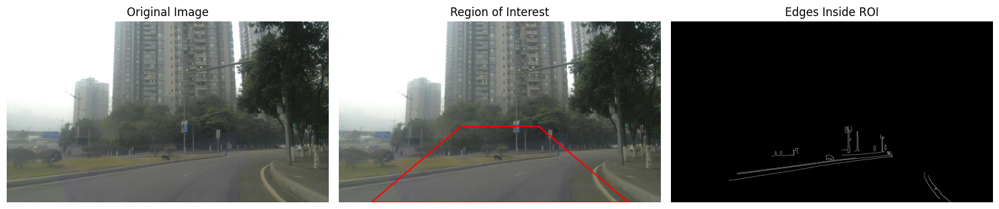

In [ ]:
roi_display = sample_image.copy()

cv2.polylines(
    roi_display,
    roi_vertices,
    True,
    (255, 0, 0),
    4
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(sample_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(roi_display)
plt.title("Region of Interest")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(roi_edges, cmap="gray")
plt.title("Edges Inside ROI")
plt.axis("off")

plt.tight_layout()
plt.show()

## ROI Experiment

Different ROI sizes are tested to compare how much of the road is retained while removing unnecessary edges outside the lane area.

In [ ]:
def apply_lane_roi(
    edges,
    bottom_left=0.05,
    top_left=0.35,
    top_right=0.65,
    bottom_right=0.95,
    top_height=0.55
):

    height, width = edges.shape

    # Define road region
    vertices = np.array([[
        (int(width * bottom_left), height),
        (int(width * top_left), int(height * top_height)),
        (int(width * top_right), int(height * top_height)),
        (int(width * bottom_right), height)
    ]], dtype=np.int32)

    # Create black mask
    mask = np.zeros_like(edges)

    # Make road region white
    cv2.fillPoly(mask, vertices, 255)

    # Keep edges inside road region
    roi_edges = cv2.bitwise_and(edges, mask)

    return roi_edges, vertices

In [ ]:
# ROI settings
roi_settings = [
    (0.05, 0.35, 0.65, 0.95, 0.55),
    (0.10, 0.38, 0.62, 0.90, 0.58),
    (0.15, 0.40, 0.60, 0.85, 0.60)
]

roi_names = [
    "Wide",
    "Medium",
    "Narrow"
]

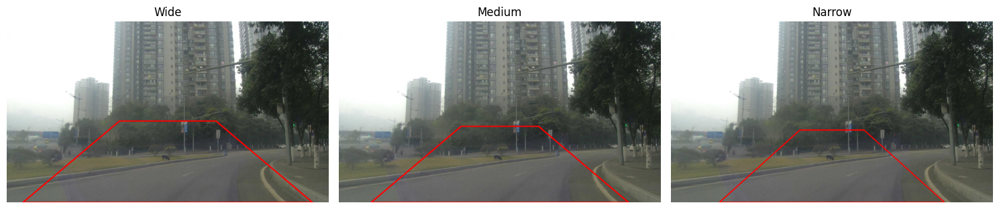

In [ ]:
plt.figure(figsize=(15, 5))

for i in range(len(roi_settings)):

    setting = roi_settings[i]

    test_roi, test_vertices = apply_lane_roi(
        edges,
        setting[0],
        setting[1],
        setting[2],
        setting[3],
        setting[4]
    )

    test_display = sample_image.copy()

    cv2.polylines(
        test_display,
        test_vertices,
        True,
        (255, 0, 0),
        4
    )

    plt.subplot(1, 3, i + 1)
    plt.imshow(test_display)
    plt.title(roi_names[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

**Observation:**

The wide ROI retained more of the visible road boundaries, particularly the curved boundary on the right side. The medium and narrow ROIs removed more unnecessary edges but also removed useful road information. Therefore, the wide ROI was selected for the next stage.

## Testing ROI on Multiple Images

The selected ROI is tested on multiple road images to check whether it captures useful road edges across different scenes.

In [ ]:
# Select multiple images for testing
random.seed(42)

sample_ids = random.sample(
    image_ids,
    6
)

print("Sample image IDs:", sample_ids)

Sample image IDs: [915, 205, 2260, 2012, 1833, 1146]


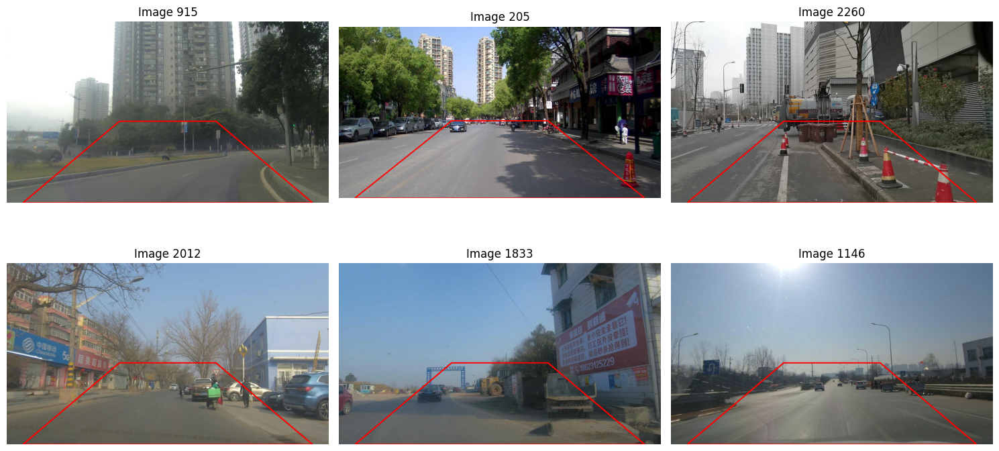

In [ ]:
plt.figure(figsize=(15, 8))

for i in range(len(sample_ids)):

    image_id = sample_ids[i]

    image = load_test_image(image_id)

    _, _, image_edges = preprocess_image(
        image,
        30,
        100
    )

    _, image_vertices = apply_lane_roi(
        image_edges,
        0.05,
        0.35,
        0.65,
        0.95,
        0.55
    )

    display_image = image.copy()

    cv2.polylines(
        display_image,
        image_vertices,
        True,
        (255, 0, 0),
        4
    )

    plt.subplot(2, 3, i + 1)
    plt.imshow(display_image)
    plt.title("Image " + str(image_id))
    plt.axis("off")

plt.tight_layout()
plt.show()

# 6. Hough Line Transform

The Hough Transform is applied to the edges inside the ROI to detect straight line segments.

These segments are possible lane or road boundaries and are filtered in the next stage.

In [ ]:
def detect_hough_lines(
    roi_edges,
    threshold=30,
    min_line_length=30,
    max_line_gap=50
):

    lines = cv2.HoughLinesP(
        roi_edges,
        1,
        np.pi / 180,
        threshold,
        minLineLength=min_line_length,
        maxLineGap=max_line_gap
    )

    return lines


hough_lines = detect_hough_lines(roi_edges)

if hough_lines is not None:
    print("Hough line segments:", len(hough_lines))
else:
    print("No Hough line segments detected")

Hough line segments: 30


In [ ]:
def draw_hough_lines(image, lines):

    output = image.copy()

    if lines is not None:

        for line in lines:

            x1, y1, x2, y2 = line[0]

            cv2.line(
                output,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                4
            )

    return output


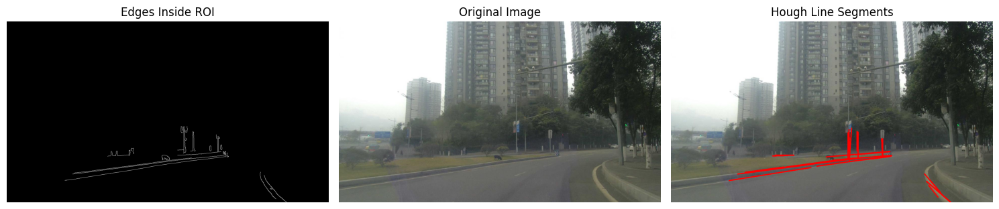

In [ ]:
hough_display = draw_hough_lines(
    sample_image,
    hough_lines
)


plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(roi_edges, cmap="gray")
plt.title("Edges Inside ROI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sample_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(hough_display)
plt.title("Hough Line Segments")
plt.axis("off")

plt.tight_layout()
plt.show()

## Hough Parameter Experiment

Different Hough Transform settings are tested to compare the number and quality of detected line segments.

Lower settings may detect more small or noisy lines, while stricter settings may miss useful road boundaries.

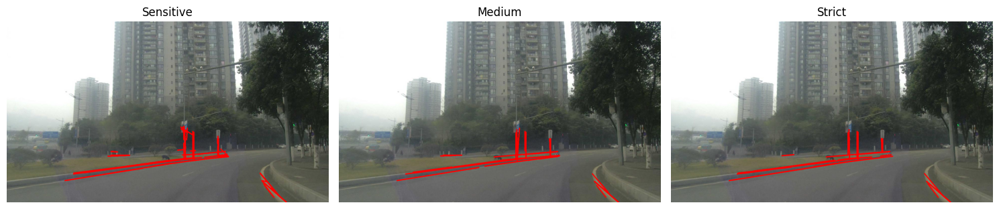

In [ ]:
hough_settings = [
    (20, 20, 30),
    (30, 30, 50),
    (40, 40, 60)
]

hough_names = [
    "Sensitive",
    "Medium",
    "Strict"
]

plt.figure(figsize=(15, 5))

for i in range(len(hough_settings)):

    setting = hough_settings[i]

    test_lines = detect_hough_lines(
        roi_edges,
        setting[0],
        setting[1],
        setting[2]
    )

    test_display = draw_hough_lines(
        sample_image,
        test_lines
    )

    plt.subplot(1, 3, i + 1)
    plt.imshow(test_display)
    plt.title(hough_names[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

**Observation:**

The sensitive settings detected more small and noisy line segments, while the strict settings removed some segments without significantly improving the detected road boundaries. The medium settings retained the main road edges with less unnecessary detection, so they were selected for the next stage.

In [ ]:
# Selected Hough settings

hough_lines = detect_hough_lines(
    roi_edges,
    30,
    30,
    50
)

# 7. Filtering Lane Candidates

The Hough Transform detects many line segments that do not represent road boundaries. The detected segments are filtered using their slope and position in the image. Negative-slope lines are considered left-side candidates and positive-slope lines are considered right-side candidates.

In [ ]:
def separate_lines(lines, min_slope=0.5, max_slope=3.0):

    left_lines = []
    right_lines = []

    if lines is None:
        return left_lines, right_lines

    for line in lines:
        x1, y1, x2, y2 = line[0]

        # Skip vertical lines (would divide by zero)
        if x1 == x2:
            continue

        slope = (y2 - y1) / (x2 - x1)
        intercept = y1 - slope * x1

        # Skip almost horizontal AND almost vertical lines
        if abs(slope) < min_slope or abs(slope) > max_slope:
            continue

        # Length of the segment (Pythagoras)
        length = np.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

        if slope < 0:
            left_lines.append([slope, intercept, length])
        else:
            right_lines.append([slope, intercept, length])

    return left_lines, right_lines

In [ ]:
def make_line(x1, y1, x2, y2):

    slope = (y2 - y1) / (x2 - x1)
    intercept = y1 - slope * x1

    return slope, intercept


def find_candidates(lines, img_w, img_h, min_slope=0.3, max_slope=2.5, min_length=25):
    # Returns left and right candidates as lists of (slope, intercept, length, x_bottom)
    left, right = [], []

    if lines is None:
        return left, right

    # Works for both OpenCV output shapes: (N, 1, 4) and (N, 4)
    lines = np.asarray(lines).reshape(-1, 4)

    centre = img_w / 2

    for x1, y1, x2, y2 in lines:

        # Skip vertical segments (slope would divide by zero)
        if x2 == x1:
            continue

        length = float(np.hypot(x2 - x1, y2 - y1))
        if length < min_length:
            continue

        slope, intercept = make_line(x1, y1, x2, y2)

        # Skip near-flat and near-vertical lines, they are not lane lines
        if abs(slope) < min_slope or abs(slope) > max_slope:
            continue

        # x position where the line reaches the bottom of the image
        x_bottom = (img_h - intercept) / slope

        # Image y points down, so a left lane line has a negative slope.
        # x_bottom must land on the road side of the image, not far off-screen
        if slope < 0 and -0.3 * img_w < x_bottom < centre:
            left.append((slope, intercept, length, x_bottom))

        elif slope > 0 and centre < x_bottom < 1.3 * img_w:
            right.append((slope, intercept, length, x_bottom))

    return left, right


def separate_lines(lines, img_w, img_h):
    # Kept for the earlier cells: returns 4 lists
    left, right = find_candidates(lines, img_w, img_h)
    return ([c[0] for c in left], [c[1] for c in left],
            [c[0] for c in right], [c[1] for c in right])


def best_line(candidates, img_w, gap=0.06, min_support=0.10):
    # Group candidates by x at the bottom of the image and keep the group with the
    # most total line length (the strongest evidence). Returns (slope, intercept),
    # or None if even the best group is too short to trust (less than 10% of the width).
    if len(candidates) == 0:
        return None

    candidates = sorted(candidates, key=lambda c: c[3])

    groups = [[candidates[0]]]
    for c in candidates[1:]:
        if c[3] - groups[-1][-1][3] <= img_w * gap:
            groups[-1].append(c)
        else:
            groups.append([c])

    best = max(groups, key=lambda g: sum(c[2] for c in g))

    if sum(c[2] for c in best) < img_w * min_support:
        return None

    weights = [c[2] for c in best]
    slope = float(np.average([c[0] for c in best], weights=weights))
    intercept = float(np.average([c[1] for c in best], weights=weights))

    return slope, intercept


def default_lane(img_w, img_h):
    # Default lane for a car in the middle of the road
    lane = {"found": False}
    lane["left_slope"], lane["left_intercept"] = make_line(
        0.25 * img_w, img_h, 0.45 * img_w, 0.6 * img_h)
    lane["right_slope"], lane["right_intercept"] = make_line(
        0.75 * img_w, img_h, 0.55 * img_w, 0.6 * img_h)
    return lane


def get_lane_edges(y, lane):

    # Rearranged from y = slope * x + intercept  ->  x = (y - intercept) / slope
    left_x = (y - lane["left_intercept"]) / lane["left_slope"]
    right_x = (y - lane["right_intercept"]) / lane["right_slope"]

    return left_x, right_x


def get_lane(lines, img_w, img_h):

    left, right = find_candidates(lines, img_w, img_h)

    left_line = best_line(left, img_w)
    right_line = best_line(right, img_w)

    # Both sides are needed, otherwise use the default lane
    if left_line is None or right_line is None:
        return default_lane(img_w, img_h)

    lane = {
        "found": True,
        "left_slope": left_line[0],
        "left_intercept": left_line[1],
        "right_slope": right_line[0],
        "right_intercept": right_line[1]
    }

    # Sanity check: the left edge must be left of the right edge at the bottom,
    # and the two lines must meet at a believable height (the vanishing point)
    left_x, right_x = get_lane_edges(img_h, lane)
    if left_x >= right_x:
        return default_lane(img_w, img_h)

    ml, bl = lane["left_slope"], lane["left_intercept"]
    mr, br = lane["right_slope"], lane["right_intercept"]
    vp_y = (bl / ml - br / mr) / (1 / ml - 1 / mr)

    if vp_y < 0.2 * img_h or vp_y > 0.8 * img_h:
        return default_lane(img_w, img_h)

    return lane


_, _, edges = preprocess_image(sample_image, 30, 100)
roi_edges, roi_vertices = apply_lane_roi(edges)
lines = detect_hough_lines(roi_edges, 30, 30, 50)

img_h, img_w = sample_image.shape[0], sample_image.shape[1]

lane = get_lane(lines, img_w, img_h)

print("Lane found:", lane["found"])

Lane found: False


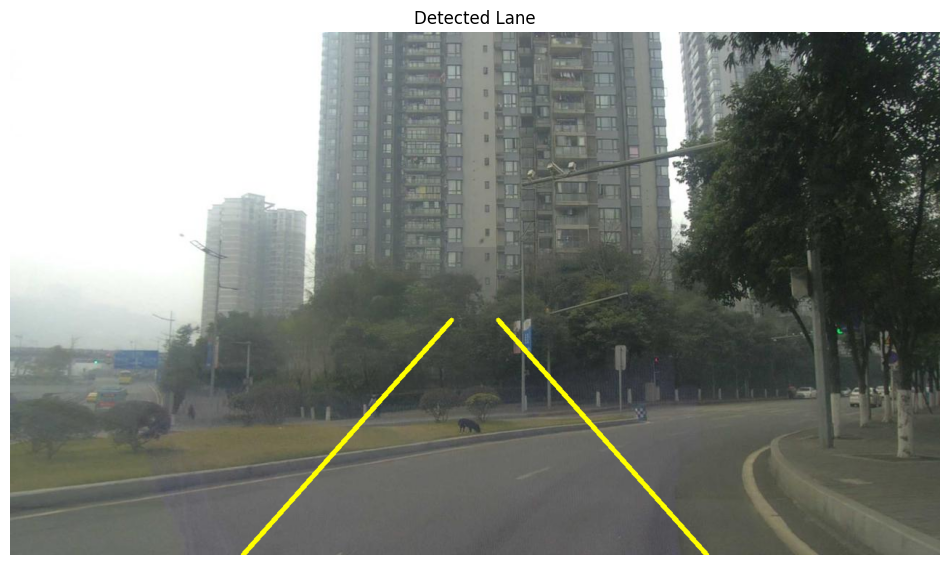

In [ ]:
def draw_lane(image, lane, top_y=0.55):

    lane_image = image.copy()
    img_h = image.shape[0]

    y_bottom = img_h
    y_top = int(img_h * top_y)

    left_bottom, right_bottom = get_lane_edges(y_bottom, lane)
    left_top, right_top = get_lane_edges(y_top, lane)

    cv2.line(lane_image, (int(left_bottom), y_bottom), (int(left_top), y_top), (255, 255, 0), 5)
    cv2.line(lane_image, (int(right_bottom), y_bottom), (int(right_top), y_top), (255, 255, 0), 5)

    return lane_image


lane_image = draw_lane(sample_image, lane)

plt.figure(figsize=(12, 7))
plt.imshow(lane_image)
plt.title("Detected Lane")
plt.axis("off")
plt.show()

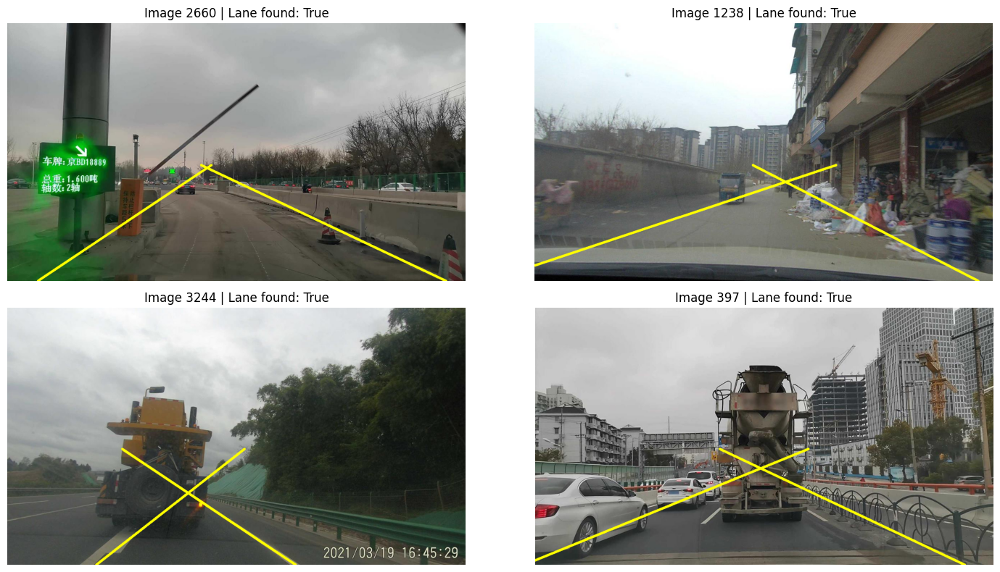

In [ ]:
def detect_lane(image):

    img_h, img_w = image.shape[0], image.shape[1]

    gray, blurred, edges = preprocess_image(image, 30, 100)
    roi_edges, roi_points = apply_lane_roi(edges)
    lines = detect_hough_lines(roi_edges)
    lane = get_lane(lines, img_w, img_h)

    return lane


# Testing on several random images
random.seed(7)
test_ids = random.sample(image_ids, 4)

plt.figure(figsize=(15, 8))

for i in range(len(test_ids)):

    test_image = load_test_image(test_ids[i])
    test_lane = detect_lane(test_image)
    test_lane_image = draw_lane(test_image, test_lane)

    plt.subplot(2, 2, i + 1)
    plt.imshow(test_lane_image)
    plt.title("Image " + str(test_ids[i]) + " | Lane found: " + str(test_lane["found"]))
    plt.axis("off")

plt.tight_layout()
plt.show()

**Observation:** Testing across multiple images showed that the 0.1 slope threshold retained useful road boundaries but also included incorrect line segments in more complex scenes. This shows that slope and position filtering alone are not enough to identify the final lane boundaries, so the remaining candidates are refined in the next stage.

## Estimating and Validating Lane Boundaries

The remaining left and right candidate segments are combined to estimate one boundary on each side of the road. The median slope and intercept are used to reduce the effect of incorrect line segments.

The estimated boundaries are then checked to determine whether they form a reasonable driving-lane region. A valid lane must have correctly positioned left and right boundaries, a suitable lane width, and become narrower towards the top of the image due to perspective.

In [ ]:
def fit_lane_boundary(lines, image_shape):

    if lines is None or len(lines) == 0:
        return None

    height, width = image_shape[:2]

    points = []

    # Collect endpoints from all candidate lines
    for line in lines:

        x1, y1, x2, y2 = line

        points.append([x1, y1])
        points.append([x2, y2])

    points = np.array(
        points,
        dtype=np.float32
    )

    # Fit one line through all candidate points
    vx, vy, x0, y0 = cv2.fitLine(
        points,
        cv2.DIST_L2,
        0,
        0.01,
        0.01
    )

    vx = float(vx[0])
    vy = float(vy[0])
    x0 = float(x0[0])
    y0 = float(y0[0])

    # Avoid almost horizontal fitted lines
    if abs(vy) < 0.001:
        return None

    # Define top and bottom of boundary
    y_bottom = height - 1
    y_top = int(height * 0.55)

    # Calculate x positions at top and bottom
    x_bottom = x0 + (
        (y_bottom - y0) * vx / vy
    )

    x_top = x0 + (
        (y_top - y0) * vx / vy
    )

    # Reject boundaries extending too far
    # outside the image
    if x_bottom < -width * 0.25:
        return None

    if x_bottom > width * 1.25:
        return None

    if x_top < -width * 0.25:
        return None

    if x_top > width * 1.25:
        return None

    return [
        int(x_bottom),
        int(y_bottom),
        int(x_top),
        int(y_top)
    ]

In [ ]:
def validate_lane_boundaries(
    left_boundary,
    right_boundary,
    image_shape
):

    if left_boundary is None or right_boundary is None:
        return False

    height, width = image_shape[:2]

    left_bottom = left_boundary[0]
    left_top = left_boundary[2]

    right_bottom = right_boundary[0]
    right_top = right_boundary[2]

    # Left boundary must stay left of right boundary
    if left_bottom >= right_bottom:
        return False

    if left_top >= right_top:
        return False

    # Calculate lane width
    bottom_width = right_bottom - left_bottom
    top_width = right_top - left_top

    # Check bottom lane width
    if bottom_width < width * 0.20:
        return False

    if bottom_width > width * 0.95:
        return False

    # Lane should become narrower towards the top
    if top_width >= bottom_width:
        return False

    # Top should not be too narrow
    if top_width < width * 0.03:
        return False

    return True

In [ ]:
def lane_to_boundaries(lane, image_shape, margin=0.06, min_top=0.50, max_top=0.80):
    # Turns the slope/intercept lane into two boundaries [x_bottom, y_bottom, x_top, y_top].
    # The lines meet at the vanishing point, so they are stopped just below it
    # (otherwise they cross and every lane would look invalid).
    height, width = image_shape[:2]

    ml, bl = lane["left_slope"], lane["left_intercept"]
    mr, br = lane["right_slope"], lane["right_intercept"]

    # Height where the left and right lines meet
    vp_y = (bl / ml - br / mr) / (1 / ml - 1 / mr)

    y_bottom = height - 1
    y_top = int(min(max(vp_y + height * margin, height * min_top), height * max_top))

    left_boundary = [int((y_bottom - bl) / ml), y_bottom, int((y_top - bl) / ml), y_top]
    right_boundary = [int((y_bottom - br) / mr), y_bottom, int((y_top - br) / mr), y_top]

    return left_boundary, right_boundary, vp_y


def check_lane_boundaries(left_boundary, right_boundary, image_shape):
    # Returns (is_valid, reason)
    height, width = image_shape[:2]

    if left_boundary[0] >= right_boundary[0] or left_boundary[2] >= right_boundary[2]:
        return False, "crossed"

    bottom_width = right_boundary[0] - left_boundary[0]
    top_width = right_boundary[2] - left_boundary[2]

    if bottom_width < width * 0.20:
        return False, "too_narrow"
    if bottom_width > width * 0.95:
        return False, "too_wide"
    if top_width >= bottom_width:
        return False, "not_narrowing"
    if top_width < width * 0.02:
        return False, "top_too_narrow"

    centre = width / 2
    if centre < left_boundary[0] - width * 0.10 or centre > right_boundary[0] + width * 0.10:
        return False, "centre_outside"

    return True, "ok"


def validate_lane_boundaries(left_boundary, right_boundary, image_shape):
    return check_lane_boundaries(left_boundary, right_boundary, image_shape)[0]


left_boundary, right_boundary, vp_y = lane_to_boundaries(lane, sample_image.shape)

lane_valid, lane_reason = check_lane_boundaries(
    left_boundary,
    right_boundary,
    sample_image.shape
)

print("Lane found from Hough lines:", lane["found"])
print("Left boundary:", left_boundary)
print("Right boundary:", right_boundary)
print("Valid driving lane:", lane_valid, "| reason:", lane_reason)

Lane found from Hough lines: False
Left boundary: [321, 719, 602, 403]
Right boundary: [959, 719, 678, 403]
Valid driving lane: True | reason: ok


In [ ]:
left_s, left_i, right_s, right_i = separate_lines(lines, img_w, img_h)

print("Hough segments:", 0 if lines is None else len(np.asarray(lines).reshape(-1, 4)))
print("Left candidates:", len(left_s))
print("Right candidates:", len(right_s))

if len(left_s) > 0 and len(right_s) > 0:
    test_lane = {
        "left_slope": float(np.median(left_s)),
        "left_intercept": float(np.median(left_i)),
        "right_slope": float(np.median(right_s)),
        "right_intercept": float(np.median(right_i))
    }
    for y in (img_h, 0.6 * img_h):
        lx, rx = get_lane_edges(y, test_lane)
        print("y =", int(y), "| left x =", int(lx), "| right x =", int(rx))

Hough segments: 40
Left candidates: 0
Right candidates: 5


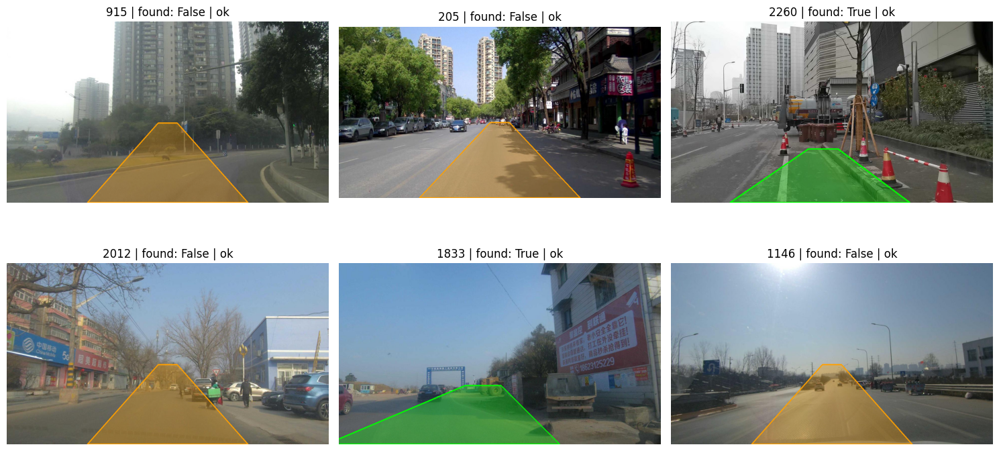

In [ ]:
plt.figure(figsize=(15, 8))

for i, image_id in enumerate(sample_ids):

    image = load_test_image(image_id)
    h, w = image.shape[0], image.shape[1]

    _, _, e = preprocess_image(image, 30, 100)
    r, _ = apply_lane_roi(e)
    hl = detect_hough_lines(r, 30, 30, 50)

    result = get_lane(hl, w, h)
    lb, rb, vp = lane_to_boundaries(result, image.shape)
    valid, reason = check_lane_boundaries(lb, rb, image.shape)

    output = image.copy()
    polygon = np.array([[lb[0], lb[1]], [lb[2], lb[3]],
                        [rb[2], rb[3]], [rb[0], rb[1]]], dtype=np.int32)

    # Green = lane found from the image, orange = default lane
    colour = (0, 255, 0) if result["found"] else (255, 160, 0)

    overlay = output.copy()
    cv2.fillPoly(overlay, [polygon], colour)
    output = cv2.addWeighted(overlay, 0.3, output, 0.7, 0)
    cv2.polylines(output, [polygon], True, colour, 4)

    plt.subplot(2, 3, i + 1)
    plt.imshow(output)
    plt.title(str(image_id) + " | found: " + str(result["found"]) + " | " + reason)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Drawing the Lane Boundaries

The estimated left and right lane boundaries are drawn on the original image to visualise the detected road boundaries. '

The left boundary is shown in red and the right boundary is shown in green.

In [ ]:
def draw_lane_boundaries(
    image,
    left_boundary,
    right_boundary
):

    output = image.copy()

    # Draw left boundary
    if left_boundary is not None:

        x1, y1, x2, y2 = left_boundary

        cv2.line(
            output,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            8
        )

    # Draw right boundary
    if right_boundary is not None:

        x1, y1, x2, y2 = right_boundary

        cv2.line(
            output,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            8
        )

    return output

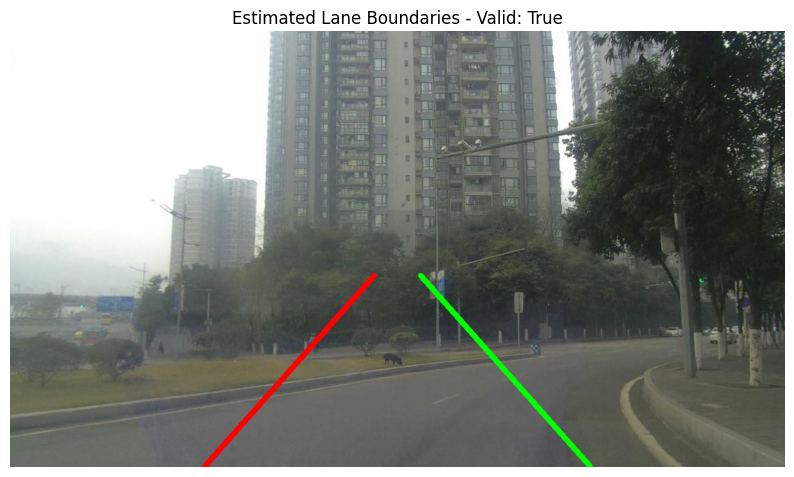

In [ ]:
boundary_display = draw_lane_boundaries(
    sample_image,
    left_boundary,
    right_boundary
)

plt.figure(figsize=(10, 6))
plt.imshow(boundary_display)

plt.title(
    "Estimated Lane Boundaries - Valid: "
    + str(lane_valid)
)

plt.axis("off")
plt.show()

## Testing Estimated Boundaries on Multiple Images

The complete lane detection pipeline is tested on multiple road images to check whether the estimated left and right boundaries remain consistent across different scenes.

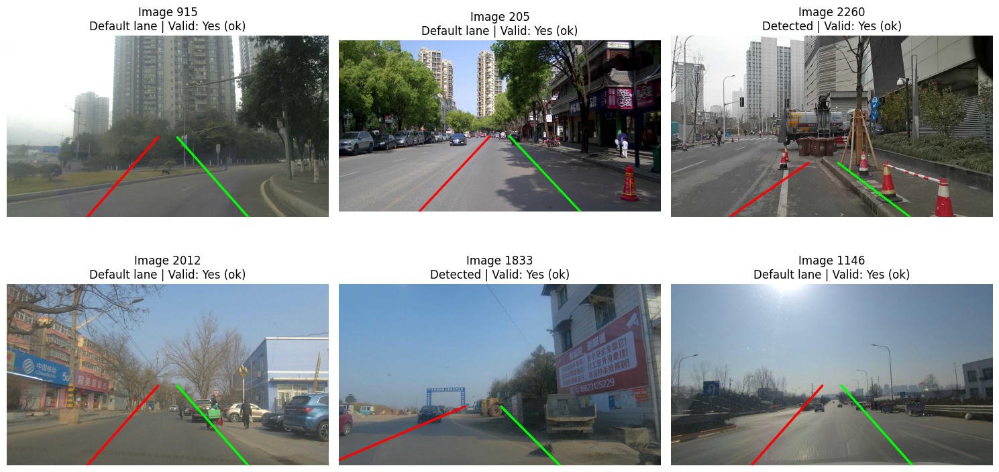

In [ ]:
plt.figure(figsize=(15, 8))

for i in range(len(sample_ids)):

    image_id = sample_ids[i]

    # Load image
    image = load_test_image(image_id)
    h, w = image.shape[0], image.shape[1]

    # Preprocess image
    _, _, image_edges = preprocess_image(image, 30, 100)

    # Apply selected wide ROI
    image_roi, _ = apply_lane_roi(image_edges, 0.05, 0.35, 0.65, 0.95, 0.55)

    # Detect Hough lines
    image_lines = detect_hough_lines(image_roi, 30, 30, 50)

    # Estimate the lane (default lane if one side is missing)
    lane_result = get_lane(image_lines, w, h)

    # Convert to boundaries and validate
    left_fit, right_fit, vp_y = lane_to_boundaries(lane_result, image.shape)
    lane_valid, lane_reason = check_lane_boundaries(left_fit, right_fit, image.shape)

    # Draw boundaries: left = red, right = green
    result = image.copy()
    cv2.line(result, (left_fit[0], left_fit[1]), (left_fit[2], left_fit[3]), (255, 0, 0), 8)
    cv2.line(result, (right_fit[0], right_fit[1]), (right_fit[2], right_fit[3]), (0, 255, 0), 8)

    plt.subplot(2, 3, i + 1)
    plt.imshow(result)

    source = "Detected" if lane_result["found"] else "Default lane"

    plt.title(
        "Image " + str(image_id) +
        "\n" + source + " | Valid: " + ("Yes" if lane_valid else "No") +
        " (" + lane_reason + ")"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
for image_id in [2260, 1833]:

    image = load_test_image(image_id)
    h, w = image.shape[0], image.shape[1]

    _, _, e = preprocess_image(image, 30, 100)
    r, _ = apply_lane_roi(e, 0.05, 0.35, 0.65, 0.95, 0.55)
    hl = detect_hough_lines(r, 30, 30, 50)

    left, right = find_candidates(hl, w, h)
    left_line = best_line(left, w)
    right_line = best_line(right, w)

    print("Image", image_id, "| size:", w, "x", h)
    print("  left candidates:", len(left), "| right candidates:", len(right))
    print("  best left line (slope, intercept):", left_line)
    print("  best right line (slope, intercept):", right_line)

    if left_line is not None and right_line is not None:
        test = {
            "left_slope": left_line[0], "left_intercept": left_line[1],
            "right_slope": right_line[0], "right_intercept": right_line[1]
        }
        for y in (h, 0.6 * h):
            lx, rx = get_lane_edges(y, test)
            print("  y =", int(y), "| left x =", int(lx), "| right x =", int(rx))



Image 2260 | size: 1280 x 720
  left candidates: 26 | right candidates: 79
  best left line (slope, intercept): (-0.6855931450449072, 880.5296768606954)
  best right line (slope, intercept): (0.7475129731058788, 9.382430894724262)
  y = 720 | left x = 234 | right x = 950
  y = 432 | left x = 654 | right x = 565
Image 1833 | size: 1281 x 720
  left candidates: 3 | right candidates: 1
  best left line (slope, intercept): (-0.4222972972972973, 698.0709459459459)
  best right line (slope, intercept): (1.0, -159.0)
  y = 720 | left x = -51 | right x = 879
  y = 432 | left x = 630 | right x = 591


In [ ]:
# Just to see if the cells have been updated
import inspect
print("min_support" in inspect.getsource(best_line))
print("0.6 * img_h" in inspect.getsource(get_lane))

True
False


**Observation:**

None of the six tested images produced a valid lane region. In most images, the estimated left and right boundaries crossed, while one image was missing a left boundary. This shows that although lane candidates can be detected, combining them into reliable lane boundaries remains difficult in complex road scenes.

# 9. Creating the Driving-Lane Region

When the estimated left and right boundaries pass the geometry validation, they are combined to create a polygon representing the driving-lane region.

In [ ]:
def create_lane_polygon(
    left_boundary,
    right_boundary,
    image_shape
):

    # Only create polygon for valid boundaries
    if not validate_lane_boundaries(
        left_boundary,
        right_boundary,
        image_shape
    ):
        return None

    left_bottom_x = left_boundary[0]
    left_bottom_y = left_boundary[1]
    left_top_x = left_boundary[2]
    left_top_y = left_boundary[3]

    right_bottom_x = right_boundary[0]
    right_bottom_y = right_boundary[1]
    right_top_x = right_boundary[2]
    right_top_y = right_boundary[3]

    polygon = np.array([
        [left_bottom_x, left_bottom_y],
        [left_top_x, left_top_y],
        [right_top_x, right_top_y],
        [right_bottom_x, right_bottom_y]
    ], dtype=np.int32)

    return polygon

In [ ]:
def draw_lane_region(
    image,
    left_boundary,
    right_boundary,
    alpha=0.30
):

    output = image.copy()

    polygon = create_lane_polygon(
        left_boundary,
        right_boundary,
        image.shape
    )

    if polygon is None:
        return output, None

    overlay = output.copy()

    # Fill lane region
    cv2.fillPoly(
        overlay,
        [polygon],
        (0, 255, 0)
    )

    # Make region transparent
    output = cv2.addWeighted(
        overlay,
        alpha,
        output,
        1 - alpha,
        0
    )

    # Draw lane outline
    cv2.polylines(
        output,
        [polygon],
        True,
        (0, 255, 0),
        4
    )

    return output, polygon

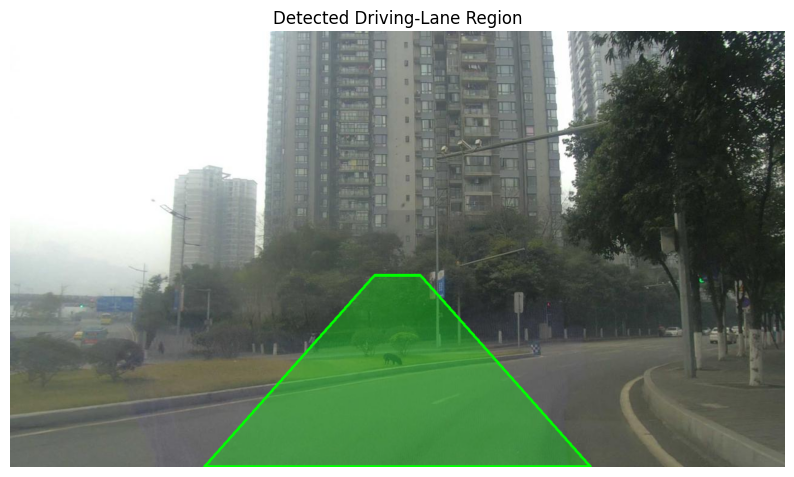

In [ ]:
lane_display, lane_polygon = draw_lane_region(
    sample_image,
    left_boundary,
    right_boundary
)

plt.figure(figsize=(10, 6))
plt.imshow(lane_display)

if lane_polygon is not None:
    plt.title("Detected Driving-Lane Region")
else:
    plt.title("Driving Lane Unavailable")

plt.axis("off")
plt.show()

# 10. Complete Lane Detection Pipeline

The previous stages are combined into one function to create the complete lane detection pipeline. This allows the same preprocessing, ROI, Hough Transform, filtering, boundary estimation and validation steps to be applied consistently to each image.

In [ ]:
def create_lane_polygon(left_boundary, right_boundary, image_shape):

    # Only create a polygon for valid boundaries
    if not validate_lane_boundaries(left_boundary, right_boundary, image_shape):
        return None

    polygon = np.array([
        [left_boundary[0], left_boundary[1]],
        [left_boundary[2], left_boundary[3]],
        [right_boundary[2], right_boundary[3]],
        [right_boundary[0], right_boundary[1]]
    ], dtype=np.int32)

    return polygon


def detect_driving_lane(image):

    height, width = image.shape[0], image.shape[1]

    # Preprocess image
    _, _, edges = preprocess_image(image, 30, 100)

    # Apply ROI
    roi_edges, _ = apply_lane_roi(edges)

    # Detect Hough lines
    hough_lines = detect_hough_lines(roi_edges, 30, 30, 50)

    # Estimate the lane (default lane if both sides are not found)
    lane = get_lane(hough_lines, width, height)

    # Convert to boundaries, stopped just below the vanishing point
    left_boundary, right_boundary, vp_y = lane_to_boundaries(lane, image.shape)

    # Validate boundaries
    is_valid, reason = check_lane_boundaries(left_boundary, right_boundary, image.shape)

    # Lane polygon for the risk stage
    lane_polygon = create_lane_polygon(left_boundary, right_boundary, image.shape)

    return {
        "lane_detected": lane["found"] and is_valid,
        "source": "detected" if lane["found"] else "fallback",
        "reason": reason,
        "left_boundary": left_boundary,
        "right_boundary": right_boundary,
        "lane_polygon": lane_polygon
    }

# 11. Lane Detection Evaluation

The final lane detection pipeline is evaluated on 500 randomly selected test images. The evaluation measures how often left and right boundaries are detected and how often they form a valid driving-lane region.

In [ ]:
random.seed(42)

lane_eval_size = 500

available_ids = list(images_by_id.keys())
lane_eval_ids = random.sample(
    available_ids,
    min(lane_eval_size, len(available_ids))
)

lane_evaluation = []

for image_id in lane_eval_ids:

    try:
        image = load_test_image(image_id)

        result = detect_driving_lane(image)

        lane_evaluation.append({
            "image_id": image_id,
            "lane_detected": result["lane_detected"],
            "left_detected": result["left_boundary"] is not None,
            "right_detected": result["right_boundary"] is not None
        })

    except Exception:

        lane_evaluation.append({
            "image_id": image_id,
            "lane_detected": False,
            "left_detected": False,
            "right_detected": False
        })

lane_eval_df = pd.DataFrame(lane_evaluation)

lane_eval_df.head()

,image_id,lane_detected,left_detected,right_detected
0,913,False,True,True
1,205,False,True,True
2,2254,False,True,True
3,2007,False,True,True
4,1829,True,True,True


## Evaluation Summary

The number of detected boundaries and valid lane regions is calculated across the evaluation images.

In [ ]:
total = len(lane_eval_df)

valid_lanes = lane_eval_df["lane_detected"].sum()

left_found = lane_eval_df["left_detected"].sum()
right_found = lane_eval_df["right_detected"].sum()

success_rate = valid_lanes / total

print("Lane Detection Evaluation")
print("-------------------------")

print("Images evaluated:", total)
print("Valid lanes detected:", valid_lanes)
print("Lane unavailable:", total - valid_lanes)
print("Valid-lane rate:", round(success_rate * 100, 1), "%")

print(
    "Left boundary found:",
    str(left_found) + "/" + str(total)
)

print(
    "Right boundary found:",
    str(right_found) + "/" + str(total)
)

Lane Detection Evaluation
-------------------------
Images evaluated: 500
Valid lanes detected: 307
Lane unavailable: 193
Valid-lane rate: 61.4 %
Left boundary found: 500/500
Right boundary found: 500/500


## Failure Analysis

Failed detections are grouped based on whether the left boundary, right boundary, both boundaries, or neither boundary was detected. This helps identify where the lane detection pipeline is failing.

In [ ]:
def lane_status(row):

    if row["lane_detected"]:
        return "Valid lane"

    if row["left_detected"] and row["right_detected"]:
        return "Both found but geometry invalid"

    if row["left_detected"]:
        return "Left only"

    if row["right_detected"]:
        return "Right only"

    return "Neither boundary"

In [ ]:
lane_eval_df["status"] = lane_eval_df.apply(
    lane_status,
    axis=1
)

status_counts = lane_eval_df["status"].value_counts()

print(status_counts)

status
Valid lane                         307
Both found but geometry invalid    193
Name: count, dtype: int64


## Qualitative Examples

Successful and failed lane detections are visualised to examine how the pipeline performs across different road scenes.

In [ ]:
successful_ids = lane_eval_df[
    lane_eval_df["lane_detected"]
]["image_id"].tolist()

failed_ids = lane_eval_df[
    lane_eval_df["lane_detected"] == False
]["image_id"].tolist()

success_examples = successful_ids[:3]
failure_examples = failed_ids[:3]

example_ids = (
    success_examples +
    failure_examples
)

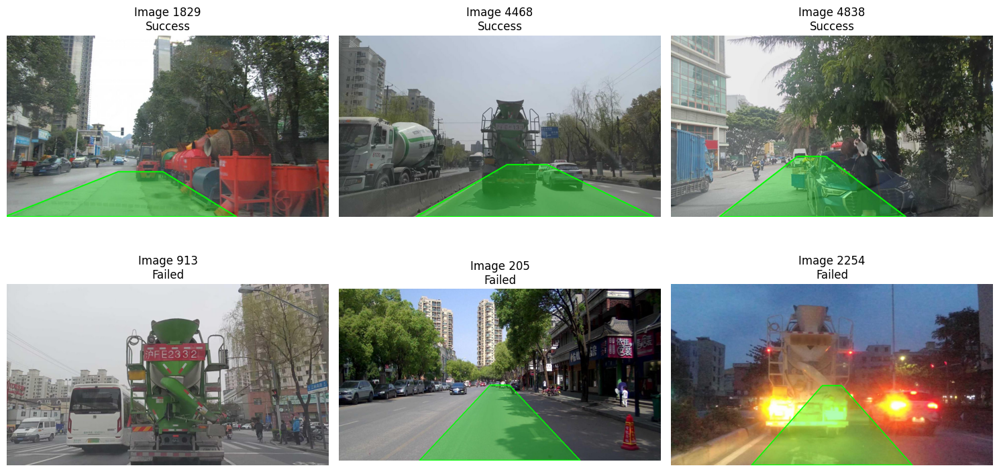

In [ ]:
plt.figure(figsize=(15, 8))

for i in range(len(example_ids)):

    image_id = example_ids[i]

    image = load_test_image(image_id)

    result = detect_driving_lane(image)

    display, polygon = draw_lane_region(
        image,
        result["left_boundary"],
        result["right_boundary"]
    )

    if result["lane_detected"]:
        status = "Success"
    else:
        status = "Failed"

    plt.subplot(2, 3, i + 1)
    plt.imshow(display)

    plt.title(
        "Image " + str(image_id) +
        "\n" + status
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## Saving Evaluation Results

The lane detection evaluation results are saved for later analysis.

In [ ]:
# Save evaluation results
lane_results_file = os.path.join(
    output_path,
    "lane_evaluation_results.csv"
)

lane_eval_df.to_csv(
    lane_results_file,
    index=False
)

print("Saved:", lane_results_file)

Saved: /content/drive/MyDrive/ippr_outputs/lane_evaluation_results.csv


# Part 3 -- Risk Assessment

This section combines the hazard detection and lane detection results to estimate the risk level of each detected hazard.

The risk assessment uses the hazard's position relative to the driving lane and its approximate proximity to the vehicle.


#Extracting Risk Features

The bottom-centre of each hazard bounding box is used to represent its position on the road. This point is checked against the detected driving-lane region to determine whether the hazard is inside or outside the lane.

The vertical position and relative size of the bounding box are also calculated to estimate how close the hazard appears to the vehicle.

In [ ]:
def get_hazard_bottom_center(bbox):

    x, y, w, h = bbox

    # Find bottom-centre of bounding box
    bottom_center_x = x + (w / 2)
    bottom_center_y = y + h

    return (
        int(bottom_center_x),
        int(bottom_center_y)
    )


In [ ]:
def hazard_in_lane(
    bbox,
    lane_polygon
):

    # Return None if lane is unavailable
    if lane_polygon is None:
        return None

    # Find bottom-centre of hazard
    point = get_hazard_bottom_center(
        bbox
    )

    # Check if point is inside lane polygon
    result = cv2.pointPolygonTest(
        lane_polygon,
        point,
        False
    )

    return result >= 0


In [ ]:
def get_proximity_features(
    bbox,
    image_shape
):

    height, width = image_shape[:2]

    x, y, w, h = bbox

    # Vertical position of bottom of object
    bottom_ratio = (y + h) / height

    # Bounding box area compared to image area
    area_ratio = (
        (w * h) /
        (width * height)
    )

    return {
        'bottom_ratio': float(bottom_ratio),
        'area_ratio': float(area_ratio)
    }

In [ ]:
def extract_risk_features(
    detection,
    lane_polygon,
    image_shape
):

    bbox = detection['bbox']

    # Find hazard contact point
    contact_point = get_hazard_bottom_center(
        bbox
    )

    # Check if hazard is inside driving lane
    in_lane = hazard_in_lane(
        bbox,
        lane_polygon
    )

    # Calculate proximity features
    proximity = get_proximity_features(
        bbox,
        image_shape
    )

    return {
        'image_id': detection['image_id'],
        'category_id': detection['category_id'],
        'class_name': cat_name.get(
            detection['category_id'],
            str(detection['category_id'])
        ),
        'confidence': detection['score'],
        'bbox': bbox,
        'contact_point': contact_point,
        'in_lane': in_lane,
        'bottom_ratio': proximity['bottom_ratio'],
        'area_ratio': proximity['area_ratio']
    }

# Selecting a Sample with a Valid Lane

An image containing both a valid detected driving lane and YOLO hazard detections is selected to test the risk assessment steps.

In [ ]:
valid_image_id = None
valid_image = None
valid_lane_result = None

# Find image with a valid lane
for image_id in detections_by_image.keys():

    image = load_test_image(image_id)

    lane_result = detect_driving_lane(
        image
    )

    if lane_result['lane_detected']:

        valid_image_id = image_id
        valid_image = image
        valid_lane_result = lane_result

        break


print("Selected image:", valid_image_id)
print(
    "Lane detected:",
    valid_lane_result['lane_detected']
)

print(
    "Detected hazards:",
    len(detections_by_image[valid_image_id])
)

Selected image: 1
Lane detected: True
Detected hazards: 23


# Extracting Risk Features

The detected hazards in the selected image are processed to extract the features used for risk assessment.

For each hazard, the class, detection confidence, position relative to the driving lane, vertical position and relative bounding-box area are recorded.

In [ ]:
# Use category names from test annotations
cat_name = category_names

sample_detections = detections_by_image[
    valid_image_id
]

risk_features = []

# Extract features for each hazard
for detection in sample_detections:

    features = extract_risk_features(
        detection,
        valid_lane_result['lane_polygon'],
        valid_image.shape
    )

    risk_features.append(features)


# Display extracted features
for features in risk_features:

    print(
        f"{features['class_name']} | "
        f"confidence={features['confidence']:.2f} | "
        f"in_lane={features['in_lane']} | "
        f"bottom={features['bottom_ratio']:.2f} | "
        f"area={features['area_ratio']:.4f}"
    )

car | confidence=0.94 | in_lane=True | bottom=1.00 | area=0.1300
cyclist | confidence=0.91 | in_lane=False | bottom=0.63 | area=0.0022
cyclist | confidence=0.89 | in_lane=False | bottom=0.70 | area=0.0077
car | confidence=0.88 | in_lane=False | bottom=0.61 | area=0.0058
bollard | confidence=0.86 | in_lane=False | bottom=1.00 | area=0.0070
bollard | confidence=0.85 | in_lane=False | bottom=0.87 | area=0.0049
cyclist | confidence=0.83 | in_lane=False | bottom=0.62 | area=0.0019
car | confidence=0.83 | in_lane=False | bottom=0.66 | area=0.0067
car | confidence=0.81 | in_lane=False | bottom=0.60 | area=0.0017
bollard | confidence=0.81 | in_lane=False | bottom=1.00 | area=0.0049
car | confidence=0.76 | in_lane=False | bottom=0.60 | area=0.0015
bollard | confidence=0.73 | in_lane=False | bottom=0.69 | area=0.0012
car | confidence=0.69 | in_lane=False | bottom=0.61 | area=0.0018
bollard | confidence=0.69 | in_lane=False | bottom=0.68 | area=0.0009
car | confidence=0.68 | in_lane=False | botto

# Visualising Hazard and Lane Positions

The detected hazards are displayed together with the estimated driving-lane region.

The bottom-centre point of each bounding box represents the hazard's position on the road. Hazards inside the driving lane are shown in green, while hazards outside the lane are shown in red.

In [ ]:
def visualise_hazard_lane_features(
    image,
    detections,
    lane_result
):

    # Draw driving-lane region
    output, polygon = draw_lane_region(
        image,
        lane_result['left_boundary'],
        lane_result['right_boundary']
    )

    for detection in detections:

        x, y, w, h = detection['bbox']

        x = int(x)
        y = int(y)
        w = int(w)
        h = int(h)

        # Get hazard class
        class_name = cat_name.get(
            detection['category_id'],
            str(detection['category_id'])
        )

        # Find bottom-centre point
        contact_point = get_hazard_bottom_center(
            detection['bbox']
        )

        # Check if hazard is inside lane
        in_lane = hazard_in_lane(
            detection['bbox'],
            polygon
        )

        # Select colour based on lane position
        if in_lane:

            color = (0, 255, 0)
            lane_text = "IN LANE"

        else:

            color = (255, 0, 0)
            lane_text = "OUTSIDE"

        # Draw bounding box
        cv2.rectangle(
            output,
            (x, y),
            (x + w, y + h),
            color,
            3
        )

        # Draw bottom-centre point
        cv2.circle(
            output,
            contact_point,
            7,
            color,
            -1
        )

        # Add hazard label
        label = (
            class_name +
            " | " +
            lane_text
        )

        cv2.putText(
            output,
            label,
            (x, max(y - 8, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            color,
            2
        )

    return output

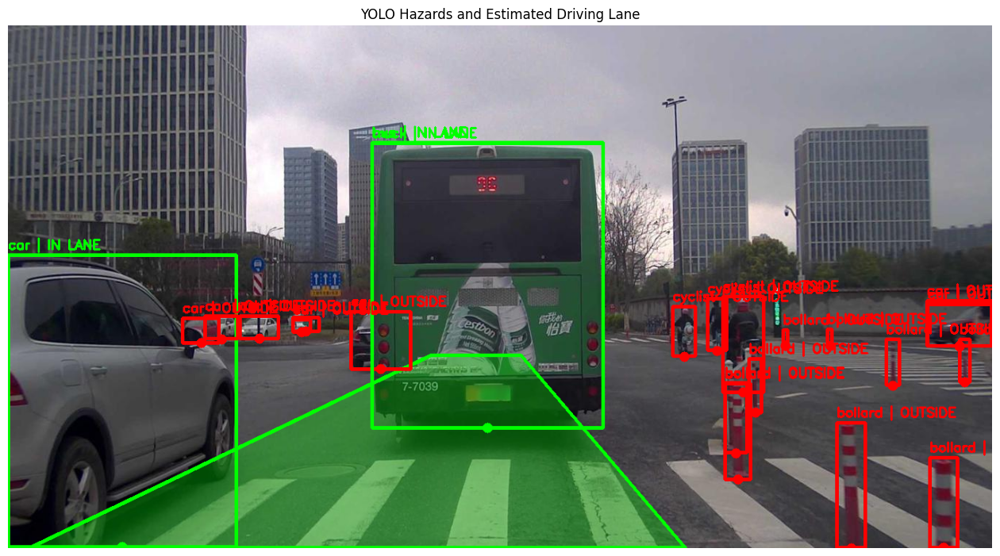

In [ ]:
feature_display = visualise_hazard_lane_features(
    valid_image,
    sample_detections,
    valid_lane_result
)

plt.figure(figsize=(16, 9))

plt.imshow(feature_display)
plt.title(
    "YOLO Hazards and Estimated Driving Lane"
)
plt.axis("off")

plt.show()

# Estimating Hazard Proximity

The apparent proximity of each hazard is estimated using its vertical position and bounding-box size relative to the image.

Hazards appearing lower or larger in the image are considered closer to the vehicle. This provides an approximate visual estimate rather than a real-world distance measurement.

In [ ]:
def estimate_proximity(
    bottom_ratio,
    area_ratio
):

    # Hazard appears near
    if bottom_ratio >= 0.80 or area_ratio >= 0.08:
        return "Near"

    # Hazard appears at medium distance
    elif bottom_ratio >= 0.65 or area_ratio >= 0.02:
        return "Medium"

    # Hazard appears far away
    else:
        return "Far"

# Classifying Hazard Risk

The risk level of each hazard is determined using its apparent proximity and position relative to the driving lane.

Hazards inside the driving lane are considered more dangerous, while hazards outside the lane are assigned a lower risk unless they appear close to the vehicle. Each hazard is classified as Low, Medium or High risk.

In [ ]:
def classify_risk(
    in_lane,
    proximity
):

    # Hazard is inside driving lane
    if in_lane is True:

        if proximity in ["Near", "Medium"]:
            return "HIGH"

        return "MEDIUM"

    # Hazard is outside driving lane
    elif in_lane is False:

        if proximity == "Near":
            return "MEDIUM"

        return "LOW"

    # Lane is unavailable
    else:

        if proximity == "Near":
            return "MEDIUM"

        return "LOW"

# Complete Risk Assessment

The extracted hazard features are combined to produce the final risk assessment.

For each detected hazard, its proximity is first estimated before the lane position and proximity are used to assign the final risk level.

In [ ]:
def assess_hazard_risk(
    detection,
    lane_polygon,
    image_shape
):

    # Extract hazard features
    features = extract_risk_features(
        detection,
        lane_polygon,
        image_shape
    )

    # Estimate hazard proximity
    proximity = estimate_proximity(
        features['bottom_ratio'],
        features['area_ratio']
    )

    # Classify hazard risk
    risk = classify_risk(
        features['in_lane'],
        proximity
    )

    # Add results to features
    features['proximity'] = proximity
    features['risk'] = risk

    return features

# Testing the Risk Assessment

The risk assessment is tested on the hazards detected in the selected image.

For each hazard, its position relative to the driving lane, estimated proximity and final risk level are displayed.

In [ ]:
risk_results = []

# Assess risk for each hazard
for detection in sample_detections:

    result = assess_hazard_risk(
        detection,
        valid_lane_result['lane_polygon'],
        valid_image.shape
    )

    risk_results.append(result)


# Display risk results
for result in risk_results:

    print(
        f"{result['class_name']:10s} | "
        f"lane={str(result['in_lane']):5s} | "
        f"proximity={result['proximity']:6s} | "
        f"risk={result['risk']}"
    )

car        | lane=True  | proximity=Near   | risk=HIGH
cyclist    | lane=False | proximity=Far    | risk=LOW
cyclist    | lane=False | proximity=Medium | risk=LOW
car        | lane=False | proximity=Far    | risk=LOW
bollard    | lane=False | proximity=Near   | risk=MEDIUM
bollard    | lane=False | proximity=Near   | risk=MEDIUM
cyclist    | lane=False | proximity=Far    | risk=LOW
car        | lane=False | proximity=Medium | risk=LOW
car        | lane=False | proximity=Far    | risk=LOW
bollard    | lane=False | proximity=Near   | risk=MEDIUM
car        | lane=False | proximity=Far    | risk=LOW
bollard    | lane=False | proximity=Medium | risk=LOW
car        | lane=False | proximity=Far    | risk=LOW
bollard    | lane=False | proximity=Medium | risk=LOW
car        | lane=False | proximity=Far    | risk=LOW
bus        | lane=True  | proximity=Near   | risk=HIGH
bollard    | lane=False | proximity=Medium | risk=LOW
bollard    | lane=False | proximity=Far    | risk=LOW
truck      | lane

# Visualising the Final Risk Assessment

The complete risk assessment is visualised by displaying each detected hazard together with its assigned risk level.

Low-risk hazards are shown in green, medium-risk hazards in yellow and high-risk hazards in red.

In [ ]:
def visualise_risk_assessment(
    image,
    detections,
    lane_result
):

    # Draw driving-lane region
    output, lane_polygon = draw_lane_region(
        image,
        lane_result['left_boundary'],
        lane_result['right_boundary']
    )

    risk_results = []

    for detection in detections:

        # Assess hazard risk
        result = assess_hazard_risk(
            detection,
            lane_polygon,
            image.shape
        )

        risk_results.append(result)

        x, y, w, h = result['bbox']

        x = int(x)
        y = int(y)
        w = int(w)
        h = int(h)

        risk = result['risk']

        # Select colour based on risk level
        if risk == "HIGH":
            color = (255, 0, 0)

        elif risk == "MEDIUM":
            color = (255, 255, 0)

        else:
            color = (0, 255, 0)

        # Draw bounding box
        cv2.rectangle(
            output,
            (x, y),
            (x + w, y + h),
            color,
            3
        )

        # Add hazard and risk label
        label = (
            f"{result['class_name']} | "
            f"{risk}"
        )

        cv2.putText(
            output,
            label,
            (x, max(y - 8, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            color,
            2
        )

    return output, risk_results

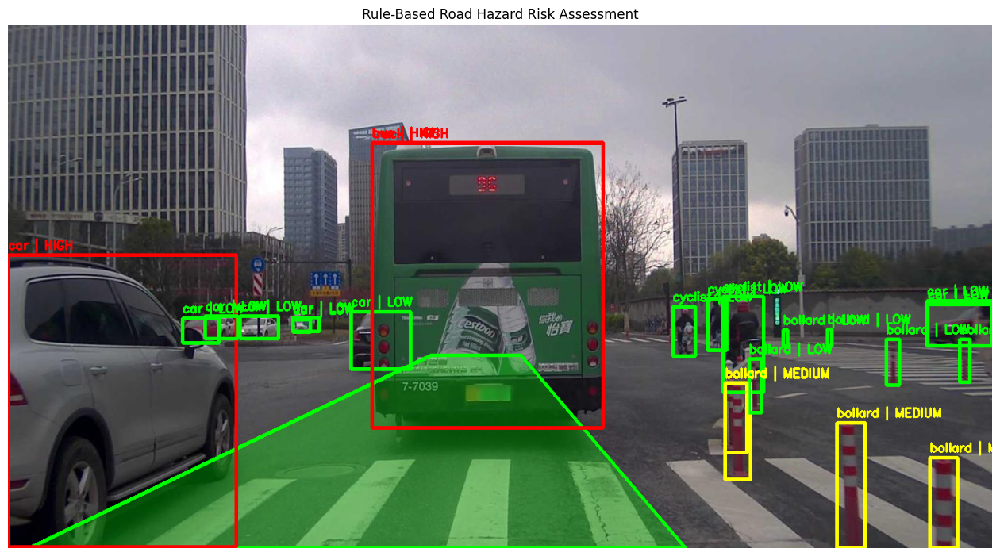

In [ ]:
final_display, final_risk_results = visualise_risk_assessment(
    valid_image,
    sample_detections,
    valid_lane_result
)

plt.figure(figsize=(16, 9))

plt.imshow(final_display)

plt.title(
    "Rule-Based Road Hazard Risk Assessment"
)

plt.axis('off')

plt.show()

# Risk Assessment Summary

The number of hazards assigned to each risk level is counted to provide a summary of the results for the selected image.

In [ ]:
from collections import Counter

# Count hazards at each risk level
risk_counts = Counter(
    result['risk']
    for result in final_risk_results
)

print("Risk Assessment Summary")
print("-----------------------")
print("HIGH:  ", risk_counts.get("HIGH", 0))
print("MEDIUM:", risk_counts.get("MEDIUM", 0))
print("LOW:   ", risk_counts.get("LOW", 0))
print("TOTAL: ", len(final_risk_results))

Risk Assessment Summary
-----------------------
HIGH:   3
MEDIUM: 4
LOW:    16
TOTAL:  23


# Testing the Risk Assessment on Multiple Images

The complete risk assessment is tested on multiple images to observe how it performs across different road scenes.

Six images containing a valid detected driving lane and at least one detected hazard are selected for testing.

In [ ]:
multi_test_ids = []

# Find images with a valid lane and detected hazards
for image_id in detections_by_image.keys():

    image = load_test_image(image_id)

    lane_result = detect_driving_lane(
        image
    )

    if (
        lane_result['lane_detected']
        and len(detections_by_image[image_id]) > 0
    ):
        multi_test_ids.append(image_id)

    # Select six images
    if len(multi_test_ids) == 6:
        break


print("Selected images:", multi_test_ids)
print("Number selected:", len(multi_test_ids))

Selected images: [1, 3, 4, 5, 6, 7]
Number selected: 6


# Visualising Risk Across Multiple Images

A cleaner visualisation is used when displaying multiple test images.

The bounding-box colour represents the assigned risk level. Labels are only displayed for Medium and High risk hazards to make the results easier to read.

In [ ]:
def visualise_risk_clean(
    image,
    detections,
    lane_result
):

    # Draw driving-lane region
    output, lane_polygon = draw_lane_region(
        image,
        lane_result['left_boundary'],
        lane_result['right_boundary']
    )

    results = []

    for detection in detections:

        # Assess hazard risk
        result = assess_hazard_risk(
            detection,
            lane_polygon,
            image.shape
        )

        results.append(result)

        x, y, w, h = map(
            int,
            result['bbox']
        )

        risk = result['risk']

        # Select colour based on risk level
        if risk == "HIGH":
            color = (255, 0, 0)

        elif risk == "MEDIUM":
            color = (255, 255, 0)

        else:
            color = (0, 255, 0)

        # Draw bounding box
        cv2.rectangle(
            output,
            (x, y),
            (x + w, y + h),
            color,
            2
        )

        # Label Medium and High risk hazards
        if risk in ["HIGH", "MEDIUM"]:

            label = (
                f"{result['class_name']} | "
                f"{risk}"
            )

            cv2.putText(
                output,
                label,
                (x, max(y - 6, 18)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45,
                color,
                1,
                cv2.LINE_AA
            )

    return output, results

# Running the Risk Assessment on Multiple Images

The complete hazard detection, lane detection and risk assessment pipeline is applied to the six selected test images.

Each image shows the detected hazards and their assigned risk levels. The number of High, Medium and Low risk hazards is also displayed above each image.

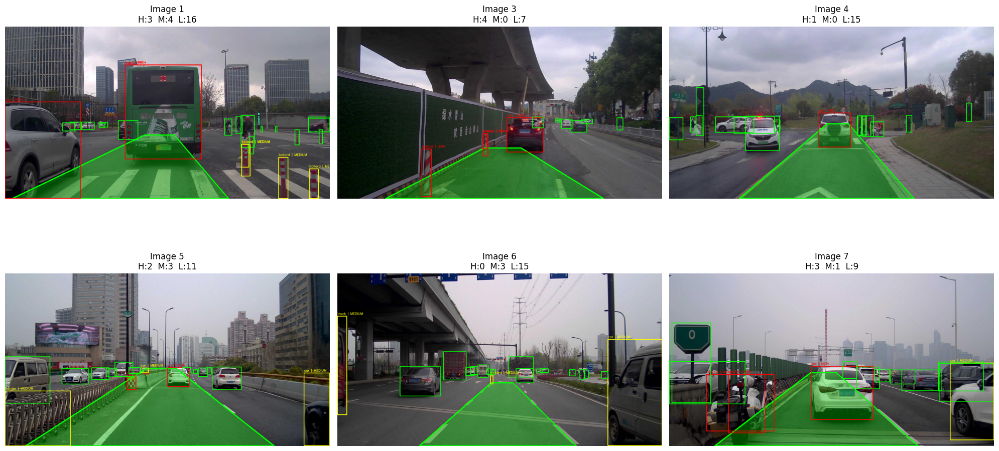

In [ ]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(20, 11)
)

all_multi_results = {}

for ax, image_id in zip(
    axes.flat,
    multi_test_ids
):

    # Load image
    image = load_test_image(image_id)

    # Detect driving lane
    lane_result = detect_driving_lane(
        image
    )

    # Get hazard detections
    detections = detections_by_image[
        image_id
    ]

    # Assess hazard risks
    display, results = visualise_risk_clean(
        image,
        detections,
        lane_result
    )

    all_multi_results[image_id] = results

    # Count risk levels
    counts = Counter(
        result['risk']
        for result in results
    )

    ax.imshow(display)

    ax.set_title(
        f"Image {image_id}\n"
        f"H:{counts.get('HIGH', 0)}  "
        f"M:{counts.get('MEDIUM', 0)}  "
        f"L:{counts.get('LOW', 0)}"
    )

    ax.axis('off')


plt.tight_layout()
plt.show()

# Multi-Image Risk Summary

The risk results from the six test images are summarised below.

The table shows the total number of detected hazards in each image and the number classified as High, Medium and Low risk.

In [ ]:
print(
    f"{'Image':<10}"
    f"{'Hazards':<10}"
    f"{'HIGH':<8}"
    f"{'MEDIUM':<10}"
    f"{'LOW':<8}"
)

print("-" * 46)

for image_id, results in all_multi_results.items():

    # Count risk levels
    counts = Counter(
        result['risk']
        for result in results
    )

    print(
        f"{image_id:<10}"
        f"{len(results):<10}"
        f"{counts.get('HIGH', 0):<8}"
        f"{counts.get('MEDIUM', 0):<10}"
        f"{counts.get('LOW', 0):<8}"
    )

Image     Hazards   HIGH    MEDIUM    LOW     
----------------------------------------------
1         23        3       4         16      
3         11        4       0         7       
4         16        1       0         15      
5         16        2       3         11      
6         18        0       3         15      
7         13        3       1         9       


# Part 4 — Risk Assessment Evaluation

The rule-based risk assessment is evaluated using a manually labelled sample of detected hazards.

Each hazard is manually classified as Low, Medium or High risk. These labels are then compared with the predicted risk levels using accuracy, precision, recall, F1-score and a confusion matrix.

# Creating the Evaluation Sample

A sample of 30 detected hazards is selected for manual evaluation.

Only images with a successfully detected driving lane are used. A maximum of three hazards is selected from each image to include hazards from different road scenes.

In [ ]:
evaluation_hazards = []

MAX_HAZARDS_PER_IMAGE = 3
TARGET_HAZARDS = 30

random.seed(42)

candidate_ids = list(
    detections_by_image.keys()
)

random.shuffle(candidate_ids)

# Select hazards for evaluation
for image_id in candidate_ids:

    if len(evaluation_hazards) >= TARGET_HAZARDS:
        break

    image = load_test_image(image_id)

    # Detect driving lane
    lane_result = detect_driving_lane(
        image
    )

    # Only use images with a valid lane
    if not lane_result['lane_detected']:
        continue

    detections = detections_by_image[
        image_id
    ]

    # Select up to three hazards
    selected = random.sample(
        detections,
        min(
            MAX_HAZARDS_PER_IMAGE,
            len(detections)
        )
    )

    for detection in selected:

        evaluation_hazards.append({
            'image_id': image_id,
            'detection': detection
        })

        if len(evaluation_hazards) >= TARGET_HAZARDS:
            break


print(
    "Hazards selected:",
    len(evaluation_hazards)
)

print(
    "Images represented:",
    len(
        set(
            item['image_id']
            for item in evaluation_hazards
        )
    )
)

Hazards selected: 30
Images represented: 12


# Displaying Hazards for Manual Labelling

Each selected hazard is displayed together with the estimated driving-lane region.

The hazard being labelled is highlighted so that its position and relationship to the driving path can be considered when assigning the risk level.

In [ ]:
def show_hazard_for_labelling(item):

    image_id = item['image_id']
    detection = item['detection']

    image = load_test_image(image_id)

    # Detect driving lane
    lane_result = detect_driving_lane(
        image
    )

    # Draw driving-lane region
    display_image, lane_polygon = draw_lane_region(
        image,
        lane_result['left_boundary'],
        lane_result['right_boundary']
    )

    x, y, w, h = map(
        int,
        detection['bbox']
    )

    # Get hazard class
    class_name = cat_name.get(
        detection['category_id'],
        str(detection['category_id'])
    )

    # Highlight target hazard
    cv2.rectangle(
        display_image,
        (x, y),
        (x + w, y + h),
        (0, 100, 255),
        6
    )

    cv2.putText(
        display_image,
        f"TARGET: {class_name}",
        (x, max(y - 10, 25)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 100, 255),
        2,
        cv2.LINE_AA
    )

    plt.figure(figsize=(14, 8))

    plt.imshow(display_image)

    plt.title(
        f"Image {image_id} — Manually Label the Highlighted Hazard"
    )

    plt.axis('off')
    plt.show()

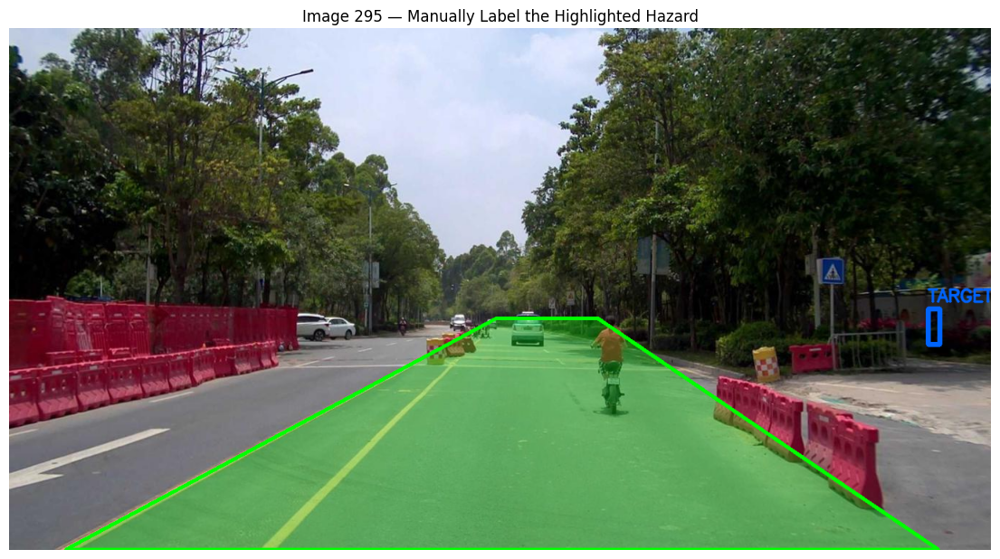

In [ ]:
show_hazard_for_labelling(
    evaluation_hazards[0]
)

# Manually Labelling Hazard Risk

Each selected hazard is manually assigned a Low, Medium or High risk label based on the road scene.

- **Low:** distant or outside the driving path
- **Medium:** potentially relevant or nearby
- **High:** immediate threat within the driving path

The selected labels are stored as the ground-truth risk labels for evaluation.

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

manual_labels = []
current_index = 0

output_widget = widgets.Output()


def display_current_hazard():

    with output_widget:

        clear_output(wait=True)

        # Check if all hazards have been labelled
        if current_index >= len(evaluation_hazards):

            print("Labelling complete!")
            print(
                "Total hazards labelled:",
                len(manual_labels)
            )

            return

        item = evaluation_hazards[
            current_index
        ]

        print(
            f"Hazard {current_index + 1} "
            f"of {len(evaluation_hazards)}"
        )

        print(
            "Choose the risk based on the scene:"
        )

        print(
            "LOW = distant / outside driving path\n"
            "MEDIUM = potentially relevant or nearby\n"
            "HIGH = immediate threat in driving path"
        )

        show_hazard_for_labelling(
            item
        )


def save_label(label):

    global current_index

    item = evaluation_hazards[
        current_index
    ]

    detection = item['detection']

    # Save selected risk label
    manual_labels.append({
        'image_id': item['image_id'],
        'category_id': detection['category_id'],
        'class_name': cat_name.get(
            detection['category_id'],
            str(detection['category_id'])
        ),
        'bbox': detection['bbox'],
        'confidence': detection['score'],
        'ground_truth': label
    })

    current_index += 1

    display_current_hazard()


# Create risk buttons
low_button = widgets.Button(
    description="LOW",
    button_style="success",
    layout=widgets.Layout(
        width="150px"
    )
)

medium_button = widgets.Button(
    description="MEDIUM",
    button_style="warning",
    layout=widgets.Layout(
        width="150px"
    )
)

high_button = widgets.Button(
    description="HIGH",
    button_style="danger",
    layout=widgets.Layout(
        width="150px"
    )
)


# Save selected label
low_button.on_click(
    lambda _: save_label("LOW")
)

medium_button.on_click(
    lambda _: save_label("MEDIUM")
)

high_button.on_click(
    lambda _: save_label("HIGH")
)


# Display labelling interface
display(
    widgets.HBox([
        low_button,
        medium_button,
        high_button
    ])
)

display(output_widget)

display_current_hazard()

Output()

# Saving the Ground-Truth Labels

The manually assigned risk labels are stored in a DataFrame and saved as a CSV file.

The distribution of Low, Medium and High risk labels is also displayed to check the final evaluation sample.

In [ ]:
# Store manual labels in DataFrame
labels_df = pd.DataFrame(
    manual_labels
)

LABELS_FILE = os.path.join(
    output_path,
    "risk_ground_truth.csv"
)

# Save ground-truth labels
labels_df.to_csv(
    LABELS_FILE,
    index=False
)

print("Saved:", LABELS_FILE)
print(
    "Labels:",
    len(labels_df)
)

print(
    "\nGround-truth distribution:"
)

print(
    labels_df[
        'ground_truth'
    ].value_counts()
)

labels_df.head()

Saved: /content/drive/MyDrive/ippr_outputs/risk_ground_truth.csv
Labels: 30

Ground-truth distribution:
ground_truth
LOW       12
MEDIUM    11
HIGH       7
Name: count, dtype: int64


,image_id,category_id,class_name,bbox,confidence,ground_truth
0,295,1,pedestrian,"[1268.92, 387.1, 16.9, 49.11]",0.3921,LOW
1,295,3,car,"[692.88, 391.78, 45.53, 47.17]",0.9120,HIGH
2,295,19,barrier,"[576.0, 427.61, 26.58, 36.47]",0.7691,MEDIUM
3,775,4,truck,"[321.61, 475.74, 95.14, 58.84]",0.7807,LOW
4,775,3,car,"[439.85, 504.94, 36.43, 30.13]",0.5787,LOW


# Generating Risk Predictions

The rule-based risk assessment is applied to each manually labelled hazard to generate a predicted risk level.

The saved hazard information is used to reconstruct each detection before applying the same risk assessment used in Part 3.

In [ ]:
import ast

# Reload saved ground-truth labels
labels_df = pd.read_csv(
    LABELS_FILE
)

predictions = []

for _, row in labels_df.iterrows():

    image_id = int(
        row['image_id']
    )

    # Load image
    image = load_test_image(
        image_id
    )

    # Detect driving lane
    lane_result = detect_driving_lane(
        image
    )

    # Convert bounding box back to list
    bbox = row['bbox']

    if isinstance(bbox, str):
        bbox = ast.literal_eval(
            bbox
        )

    # Reconstruct detection
    detection = {
        'image_id': image_id,
        'category_id': int(
            row['category_id']
        ),
        'bbox': bbox,
        'score': float(
            row['confidence']
        )
    }

    # Predict hazard risk
    result = assess_hazard_risk(
        detection,
        lane_result['lane_polygon'],
        image.shape
    )

    predictions.append(
        result['risk']
    )


# Add predictions to DataFrame
labels_df['predicted_risk'] = predictions

print(
    labels_df[
        [
            'image_id',
            'class_name',
            'ground_truth',
            'predicted_risk'
        ]
    ]
)

print(
    "\nPredictions generated:",
    len(predictions)
)

    image_id            class_name ground_truth predicted_risk
0        295            pedestrian          LOW            LOW
1        295                   car         HIGH         MEDIUM
2        295               barrier       MEDIUM         MEDIUM
3        775                 truck          LOW            LOW
4        775                   car          LOW            LOW
5        775                   car          LOW            LOW
6       2909                 truck       MEDIUM           HIGH
7       2909            pedestrian          LOW           HIGH
8       2909               cyclist          LOW           HIGH
9       3326                   car       MEDIUM           HIGH
10      3326                   car       MEDIUM         MEDIUM
11      3326              tricycle       MEDIUM         MEDIUM
12       903                   car       MEDIUM         MEDIUM
13       903          traffic_sign         HIGH           HIGH
14      1209            pedestrian          LOW        

# Evaluating Risk Classification

The predicted risk levels are compared with the manually assigned ground-truth labels.

Accuracy is calculated for overall performance, while macro precision, recall and F1-score are used to evaluate performance across the Low, Medium and High risk classes.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Ground-truth and predicted labels
y_true = labels_df[
    'ground_truth'
]

y_pred = labels_df[
    'predicted_risk'
]

risk_labels = [
    'LOW',
    'MEDIUM',
    'HIGH'
]


# Calculate evaluation metrics
accuracy = accuracy_score(
    y_true,
    y_pred
)

macro_precision = precision_score(
    y_true,
    y_pred,
    labels=risk_labels,
    average='macro',
    zero_division=0
)

macro_recall = recall_score(
    y_true,
    y_pred,
    labels=risk_labels,
    average='macro',
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=risk_labels,
    average='macro',
    zero_division=0
)


# Display results
print("Risk Assessment Results")
print("-----------------------")

print(
    f"Accuracy:        {accuracy:.3f}"
)

print(
    f"Macro Precision: {macro_precision:.3f}"
)

print(
    f"Macro Recall:    {macro_recall:.3f}"
)

print(
    f"Macro F1-score:  {macro_f1:.3f}"
)

print(
    "\nClassification Report:"
)

print(
    classification_report(
        y_true,
        y_pred,
        labels=risk_labels,
        zero_division=0
    )
)

Risk Assessment Results
-----------------------
Accuracy:        0.600
Macro Precision: 0.620
Macro Recall:    0.614
Macro F1-score:  0.598

Classification Report:
              precision    recall  f1-score   support

         LOW       0.78      0.58      0.67        12
      MEDIUM       0.67      0.55      0.60        11
        HIGH       0.42      0.71      0.53         7

    accuracy                           0.60        30
   macro avg       0.62      0.61      0.60        30
weighted avg       0.65      0.60      0.61        30



# Confusion Matrix

A confusion matrix is used to compare the predicted and actual risk classes.

This shows which Low, Medium and High risk hazards were classified correctly and where misclassifications occurred.

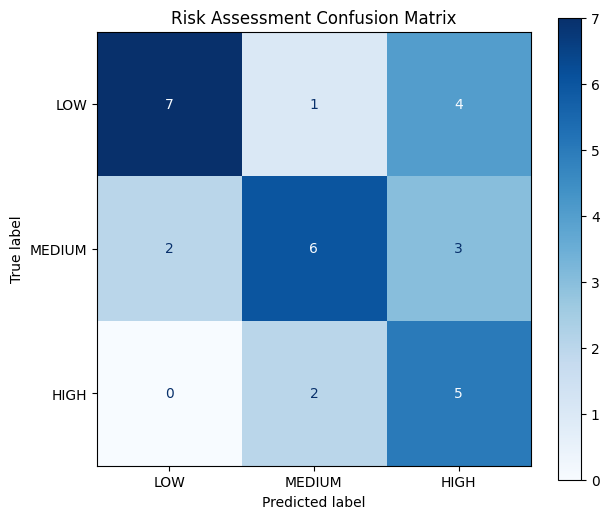

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Create confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=risk_labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=risk_labels
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp.plot(
    ax=ax,
    cmap='Blues',
    values_format='d'
)

plt.title(
    "Risk Assessment Confusion Matrix"
)

plt.show()

# High-Risk Recall

High-Risk Recall measures how many of the manually labelled High risk hazards were correctly identified by the risk assessment system.

This is particularly important because missing a High risk hazard could represent a more serious error in a road-safety system.

In [ ]:
# Find actual and predicted High risk hazards
high_true = (
    y_true == 'HIGH'
)

high_pred = (
    y_pred == 'HIGH'
)

# Count correctly identified High risk hazards
true_high = (
    (high_true) & (high_pred)
).sum()

total_high = high_true.sum()

# Calculate High-Risk Recall
high_risk_recall = (
    true_high / total_high
    if total_high > 0
    else 0
)

print(
    "True HIGH hazards:",
    total_high
)

print(
    "Correctly detected HIGH hazards:",
    true_high
)

print(
    f"High-Risk Recall: {high_risk_recall:.3f}"
)

True HIGH hazards: 7
Correctly detected HIGH hazards: 5
High-Risk Recall: 0.714


# Saving the Evaluation Results

The final risk evaluation results are saved as a CSV file for later analysis.

In [ ]:
RISK_RESULTS_FILE = os.path.join(
    output_path,
    "risk_evaluation_results.csv"
)

# Save final evaluation results
labels_df.to_csv(
    RISK_RESULTS_FILE,
    index=False
)

print(
    "Saved:",
    RISK_RESULTS_FILE
)

Saved: /content/drive/MyDrive/ippr_outputs/risk_evaluation_results.csv
